In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# --- 1. Setup Model ---
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

model = GPT2LMHeadModel.from_pretrained('gpt2').to(device)
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
model.eval()

# Freeze model to save memory/compute (we only optimize the path)
for param in model.parameters():
    param.requires_grad = False


Using device: cuda


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [ ]:
# --- 2. Helper Functions ---

def get_layer0_and_prefix(prompt):
    """
    Returns:
    1. The Layer 0 output for the whole sequence (to get the context).
    2. The input_ids (to check sequence length).
    """
    tokens = tokenizer(prompt, return_tensors='pt').to(device)
    input_ids = tokens['input_ids']

    # Compute embeddings (WTE + WPE)
    wte = model.transformer.wte(input_ids)
    positions = torch.arange(input_ids.shape[1], device=device).unsqueeze(0)
    wpe = model.transformer.wpe(positions)
    hidden_states = wte + wpe

    # Pass through Drop -> Block 0
    hidden_states = model.transformer.drop(hidden_states)
    hidden_states = model.transformer.h[0](hidden_states)[0]

    return hidden_states, input_ids

def slerp_path(v0, v1, n_steps):
    """Generates a static Slerp path between two vectors."""
    t_values = torch.linspace(0, 1, n_steps, device=device)
    v0_flat = v0.flatten()
    v1_flat = v1.flatten()

    norm0 = torch.norm(v0_flat)
    norm1 = torch.norm(v1_flat)
    v0_unit = v0_flat / norm0
    v1_unit = v1_flat / norm1

    dot = torch.clamp(torch.dot(v0_unit, v1_unit), -1.0, 1.0)
    theta = torch.acos(dot)

    path = []
    for t in t_values:
        if theta.abs() < 1e-6:
            direction = v0_unit
        else:
            sin_theta = torch.sin(theta)
            direction = (torch.sin((1 - t) * theta) / sin_theta) * v0_unit + \
                        (torch.sin(t * theta) / sin_theta) * v1_unit

        mag = (1 - t) * norm0 + t * norm1
        path.append(direction * mag)

    # FIX: Correctly reshape to [Steps, 1, Hidden]
    # v0 shape is [1, 1, 768]. We want [50, 1, 768].
    return torch.stack(path).reshape(n_steps, v0.shape[-2], v0.shape[-1])

def forward_batch_from_layer1(prefix_resid, path_vectors):
    """
    Args:
        prefix_resid: [1, seq_len-1, hidden_dim] (Fixed context)
        path_vectors: [N_steps, 1, hidden_dim] (The path we are optimizing)
    Returns:
        logits: [N_steps, vocab_size] (Only for the last token)
    """
    n_steps = path_vectors.shape[0]

    # Expand prefix to match batch size N
    # prefix_batch: [N, seq_len-1, hidden_dim]
    prefix_batch = prefix_resid.expand(n_steps, -1, -1)

    # Concatenate prefix with the current path vector
    # sequence_batch: [N, seq_len, hidden_dim]
    sequence_batch = torch.cat([prefix_batch, path_vectors], dim=1)

    hidden = sequence_batch

    # Pass through remaining layers (1 to 11)
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]

    hidden = model.transformer.ln_f(hidden)

    # Get logits only for the last token in the sequence
    last_token_hidden = hidden[:, -1, :]
    logits = model.lm_head(last_token_hidden)

    return logits


In [ ]:
# --- 3. The Experiment Setup ---

prompt_a = "The house was big"
prompt_b = "The house was large"
n_steps = 50
lambda_val = 1.0
lr = 0.05
iterations = 200

print(f"Optimizing path between: '{prompt_a}' and '{prompt_b}'")

# Get Endpoints
resid_a, _ = get_layer0_and_prefix(prompt_a)
resid_b, _ = get_layer0_and_prefix(prompt_b)

# Separate Prefix (Context) from Target (Last Token)
prefix_resid = resid_a[:, :-1, :]  # "The house was"
start_vec = resid_a[:, -1:, :]     # " big"
end_vec = resid_b[:, -1:, :]       # " large"

# Initialize Path with Slerp
initial_path = slerp_path(start_vec, end_vec, n_steps)

# Make it a trainable parameter
# We clone it so we can keep 'initial_path' for comparison later
optimized_path = nn.Parameter(initial_path.clone().detach())

# Optimizer
optimizer = optim.Adam([optimized_path], lr=lr)

# Logging
loss_history = []
velocity_history = []

Optimizing path between: 'The house was big' and 'The house was large'


In [ ]:
# --- 4. The Optimization Loop ---

print("\nStarting Optimization...")
for i in range(iterations):
    optimizer.zero_grad()

    # 1. Forward Pass (Batch)
    current_logits = forward_batch_from_layer1(prefix_resid, optimized_path)

    # 2. Compute Energies (Cost Function)

    # Input Kinetic Energy: sum || P[t+1] - P[t] ||^2
    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    # Output Kinetic Energy: sum || f(P[t+1]) - f(P[t]) ||^2
    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    # Total Lagrangian
    loss = energy_input + (lambda_val * energy_output)

    # 3. Backward & Step
    loss.backward()
    optimizer.step()

    # 4. Boundary Constraint
    with torch.no_grad():
        # optimized_path[0] is [1, 768]
        # start_vec is [1, 1, 768] -> reshape to [1, 768]
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    loss_history.append(loss.item())
    if i % 20 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f} "
              f"(In: {energy_input.item():.2f}, Out: {energy_output.item():.2f})")


Starting Optimization...
Iter 000: Loss 53807.60 (In: 16.07, Out: 53791.54)
Iter 020: Loss 1178357.75 (In: 103.21, Out: 1178254.50)
Iter 040: Loss 226689.20 (In: 126.60, Out: 226562.61)
Iter 060: Loss 93979.62 (In: 128.29, Out: 93851.33)
Iter 080: Loss 61489.36 (In: 121.11, Out: 61368.25)
Iter 100: Loss 54711.51 (In: 112.98, Out: 54598.54)
Iter 120: Loss 53593.38 (In: 105.85, Out: 53487.53)
Iter 140: Loss 53439.80 (In: 99.75, Out: 53340.05)
Iter 160: Loss 53386.54 (In: 94.48, Out: 53292.06)
Iter 180: Loss 53346.29 (In: 89.86, Out: 53256.43)



Computing final profiles...


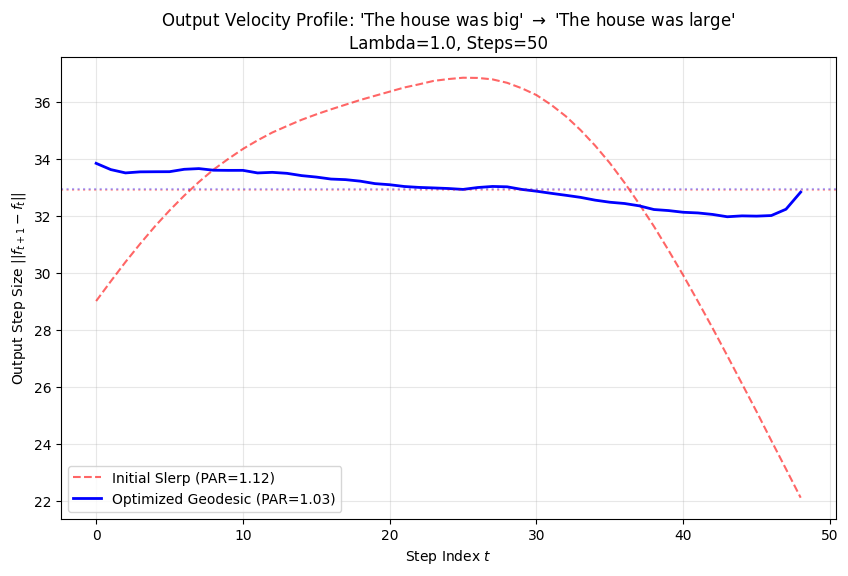

--------------------------------------------------
Initial Peak-to-Average Ratio:   1.12
Optimized Peak-to-Average Ratio: 1.03


In [ ]:
# --- 5. Analysis & Visualization ---

def compute_velocity_profile(path_tensor):
    """Computes ||f(t+1) - f(t)|| for the whole path."""
    with torch.no_grad():
        logits = forward_batch_from_layer1(prefix_resid, path_tensor)
        diffs = logits[1:] - logits[:-1]
        velocities = diffs.norm(dim=1).cpu().numpy()
    return velocities

print("\nComputing final profiles...")
vel_initial = compute_velocity_profile(initial_path)
vel_optimized = compute_velocity_profile(optimized_path)

# Metrics (Peak-to-Average Ratio)
par_initial = np.max(vel_initial) / np.mean(vel_initial)
par_optimized = np.max(vel_optimized) / np.mean(vel_optimized)

# Plotting
plt.figure(figsize=(10, 6))

plt.plot(vel_initial, label=f'Initial Slerp (PAR={par_initial:.2f})',
         color='red', linestyle='--', alpha=0.6)
plt.plot(vel_optimized, label=f'Optimized Geodesic (PAR={par_optimized:.2f})',
         color='blue', linewidth=2)

# Draw Mean lines
plt.axhline(y=np.mean(vel_initial), color='red', linestyle=':', alpha=0.3)
plt.axhline(y=np.mean(vel_optimized), color='blue', linestyle=':', alpha=0.3)

plt.title(f"Output Velocity Profile: '{prompt_a}' $\\to$ '{prompt_b}'\n"
          f"Lambda={lambda_val}, Steps={n_steps}")
plt.xlabel("Step Index $t$")
plt.ylabel("Output Step Size $||f_{t+1} - f_t||$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Interpretation
print("-" * 50)
print(f"Initial Peak-to-Average Ratio:   {par_initial:.2f}")
print(f"Optimized Peak-to-Average Ratio: {par_optimized:.2f}")

Now to do the same thing with "The house was big" vs "The house was in"

Optimizing path between: 'The house was big' and 'The house was in'

Starting Optimization...
Iter 000: Loss 11880571.00 (In: 29.74, Out: 11880541.00)
Iter 020: Loss 3948912.50 (In: 479.12, Out: 3948433.50)
Iter 040: Loss 1477346.12 (In: 649.54, Out: 1476696.62)
Iter 060: Loss 999547.31 (In: 663.55, Out: 998883.75)
Iter 080: Loss 827315.31 (In: 648.56, Out: 826666.75)
Iter 100: Loss 738506.38 (In: 636.53, Out: 737869.81)
Iter 120: Loss 689051.12 (In: 628.38, Out: 688422.75)
Iter 140: Loss 622031.69 (In: 624.04, Out: 621407.62)
Iter 160: Loss 562485.88 (In: 621.63, Out: 561864.25)
Iter 180: Loss 474311.47 (In: 621.10, Out: 473690.38)
Iter 200: Loss 305421.66 (In: 606.52, Out: 304815.12)
Iter 220: Loss 229610.77 (In: 597.73, Out: 229013.03)
Iter 240: Loss 203542.88 (In: 592.54, Out: 202950.34)
Iter 260: Loss 187641.44 (In: 587.81, Out: 187053.62)
Iter 280: Loss 176235.33 (In: 583.42, Out: 175651.91)
Iter 300: Loss 167608.89 (In: 579.24, Out: 167029.66)
Iter 320: Loss 165446.56 (In: 575.1

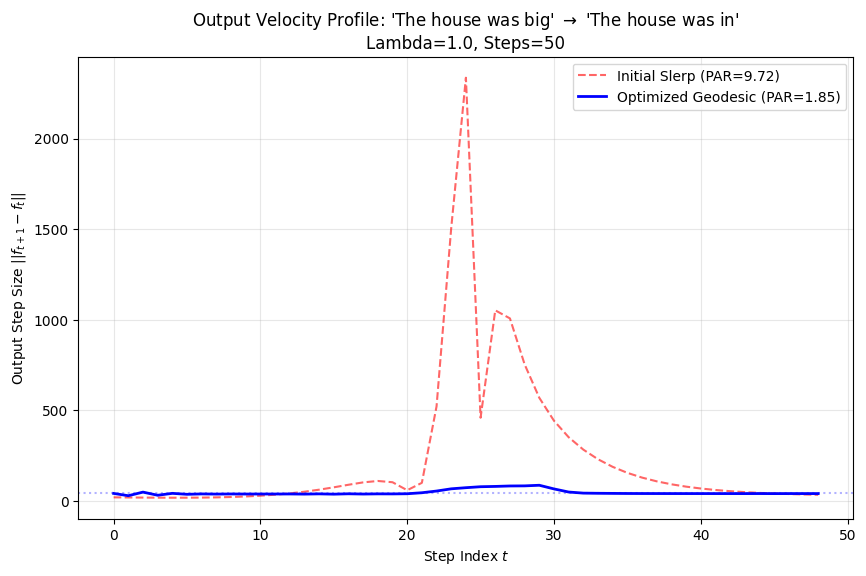

--------------------------------------------------
Initial Peak-to-Average Ratio:   9.72
Optimized Peak-to-Average Ratio: 1.85


In [ ]:
# --- 3. The Experiment Setup ---

prompt_a = "The house was big"
prompt_b = "The house was in"
n_steps = 50
lambda_val = 1.0
lr = 0.05
iterations = 1000

print(f"Optimizing path between: '{prompt_a}' and '{prompt_b}'")

# Get Endpoints
resid_a, _ = get_layer0_and_prefix(prompt_a)
resid_b, _ = get_layer0_and_prefix(prompt_b)

# Separate Prefix (Context) from Target (Last Token)
prefix_resid = resid_a[:, :-1, :]  # "The house was"
start_vec = resid_a[:, -1:, :]     # " big"
end_vec = resid_b[:, -1:, :]       # " large"

# Initialize Path with Slerp
initial_path = slerp_path(start_vec, end_vec, n_steps)

# Make it a trainable parameter
# We clone it so we can keep 'initial_path' for comparison later
optimized_path = nn.Parameter(initial_path.clone().detach())

# Optimizer
optimizer = optim.Adam([optimized_path], lr=lr)

# Logging
loss_history = []
velocity_history = []

# --- 4. The Optimization Loop ---

print("\nStarting Optimization...")
for i in range(iterations):
    optimizer.zero_grad()

    # 1. Forward Pass (Batch)
    current_logits = forward_batch_from_layer1(prefix_resid, optimized_path)

    # 2. Compute Energies (Cost Function)

    # Input Kinetic Energy: sum || P[t+1] - P[t] ||^2
    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    # Output Kinetic Energy: sum || f(P[t+1]) - f(P[t]) ||^2
    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    # Total Lagrangian
    loss = energy_input + (lambda_val * energy_output)

    # 3. Backward & Step
    loss.backward()
    optimizer.step()

    # 4. Boundary Constraint
    with torch.no_grad():
        # optimized_path[0] is [1, 768]
        # start_vec is [1, 1, 768] -> reshape to [1, 768]
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    loss_history.append(loss.item())
    if i % 20 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f} "
              f"(In: {energy_input.item():.2f}, Out: {energy_output.item():.2f})")

# --- 5. Analysis & Visualization ---

def compute_velocity_profile(path_tensor):
    """Computes ||f(t+1) - f(t)|| for the whole path."""
    with torch.no_grad():
        logits = forward_batch_from_layer1(prefix_resid, path_tensor)
        diffs = logits[1:] - logits[:-1]
        velocities = diffs.norm(dim=1).cpu().numpy()
    return velocities

print("\nComputing final profiles...")
vel_initial = compute_velocity_profile(initial_path)
vel_optimized = compute_velocity_profile(optimized_path)

# Metrics (Peak-to-Average Ratio)
par_initial = np.max(vel_initial) / np.mean(vel_initial)
par_optimized = np.max(vel_optimized) / np.mean(vel_optimized)

# Plotting
plt.figure(figsize=(10, 6))

plt.plot(vel_initial, label=f'Initial Slerp (PAR={par_initial:.2f})',
         color='red', linestyle='--', alpha=0.6)
plt.plot(vel_optimized, label=f'Optimized Geodesic (PAR={par_optimized:.2f})',
         color='blue', linewidth=2)

# Draw Mean lines
# plt.axhline(y=np.mean(vel_initial), color='red', linestyle=':', alpha=0.3)
plt.axhline(y=np.mean(vel_optimized), color='blue', linestyle=':', alpha=0.3)

plt.title(f"Output Velocity Profile: '{prompt_a}' $\\to$ '{prompt_b}'\n"
          f"Lambda={lambda_val}, Steps={n_steps}")
plt.xlabel("Step Index $t$")
plt.ylabel("Output Step Size $||f_{t+1} - f_t||$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Interpretation
print("-" * 50)
print(f"Initial Peak-to-Average Ratio:   {par_initial:.2f}")
print(f"Optimized Peak-to-Average Ratio: {par_optimized:.2f}")




Computing final profiles...


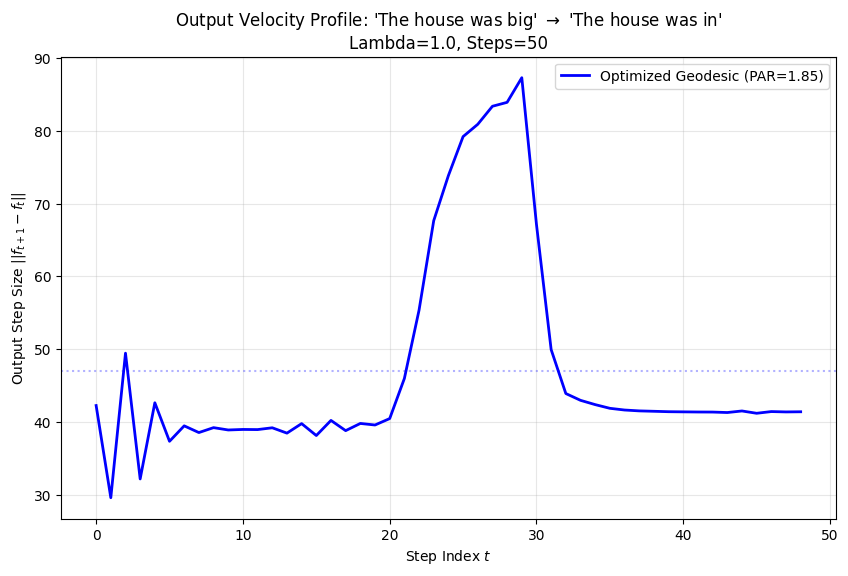

--------------------------------------------------
Initial Peak-to-Average Ratio:   9.72
Optimized Peak-to-Average Ratio: 1.85


In [ ]:
print("\nComputing final profiles...")
vel_initial = compute_velocity_profile(initial_path)
vel_optimized = compute_velocity_profile(optimized_path)

# Metrics (Peak-to-Average Ratio)
par_initial = np.max(vel_initial) / np.mean(vel_initial)
par_optimized = np.max(vel_optimized) / np.mean(vel_optimized)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(vel_optimized, label=f'Optimized Geodesic (PAR={par_optimized:.2f})',
         color='blue', linewidth=2)

# Draw Mean lines
# plt.axhline(y=np.mean(vel_initial), color='red', linestyle=':', alpha=0.3)
plt.axhline(y=np.mean(vel_optimized), color='blue', linestyle=':', alpha=0.3)

plt.title(f"Output Velocity Profile: '{prompt_a}' $\\to$ '{prompt_b}'\n"
          f"Lambda={lambda_val}, Steps={n_steps}")
plt.xlabel("Step Index $t$")
plt.ylabel("Output Step Size $||f_{t+1} - f_t||$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Interpretation
print("-" * 50)
print(f"Initial Peak-to-Average Ratio:   {par_initial:.2f}")
print(f"Optimized Peak-to-Average Ratio: {par_optimized:.2f}")



The output velocity profile for "The house was big" -> "The house was large" is fairly flat. Our score (peak-to-average ratio, PAR) for the optimized path is 1.05. The slerp path already had 1.12, so it was also fairly flat. This provides support for the 'same-activation-region' hypothesis, and validates the working of the method.

It is interesting to note that the velocity actually peaks at the beginning and end of the path! I am not sure how to interpret that. Even within this relatively flat plateau, we have minima for the specific outputs?

The output velocity profile for "The house was big" -> "The house was in" is definitely less flat, with a PAR of 1.85 (slerp path had 9.72; so our optimization found a much 'stabler' path). There is a distinct peak around step indices 25-30, which can be interpreted as the boundary between activation plateaus, to use the language of Stefan's LessWrong post. There's also quite a bit of instability in steps ~0-5: some wiggling happens. Not sure what that's about!

We have introduced a hyperparameter: the weight $\lambda$ which appears in the definition of our cost function. Naturally the optimal path depends on this weight. Large values of $\lambda$ prioritize 'stable' paths over 'short' paths. From the perspective of inquiring on the existence of stable paths, might it make more sense to have a metric that massively prioritizes 'stability' over 'shortness'? In other words, set $\lambda$ to infinity (or, more practically, set the first term to zero)? If even this cannot find a stable path, that constitutes fairly strong evidence that the outputs live in different output regions. Let's try to d o that for big and in.

Optimizing path between: 'The house was big' and 'The house was in'

Starting Optimization...
Iter 000: Loss 11880541.00 (In: 29.74, Out: 11880541.00)
Iter 020: Loss 3940370.50 (In: 479.44, Out: 3940370.50)
Iter 040: Loss 1479209.75 (In: 651.06, Out: 1479209.75)
Iter 060: Loss 998669.06 (In: 666.93, Out: 998669.06)
Iter 080: Loss 826502.50 (In: 653.82, Out: 826502.50)
Iter 100: Loss 737658.25 (In: 643.73, Out: 737658.25)
Iter 120: Loss 687617.44 (In: 637.56, Out: 687617.44)
Iter 140: Loss 621029.00 (In: 635.05, Out: 621029.00)
Iter 160: Loss 562129.75 (In: 634.54, Out: 562129.75)
Iter 180: Loss 474344.12 (In: 635.99, Out: 474344.12)
Iter 200: Loss 305599.44 (In: 623.49, Out: 305599.44)
Iter 220: Loss 229145.81 (In: 616.58, Out: 229145.81)
Iter 240: Loss 202988.34 (In: 613.31, Out: 202988.34)
Iter 260: Loss 187078.75 (In: 610.46, Out: 187078.75)
Iter 280: Loss 178353.53 (In: 607.81, Out: 178353.53)
Iter 300: Loss 167015.62 (In: 606.30, Out: 167015.62)
Iter 320: Loss 160410.33 (In: 604.3

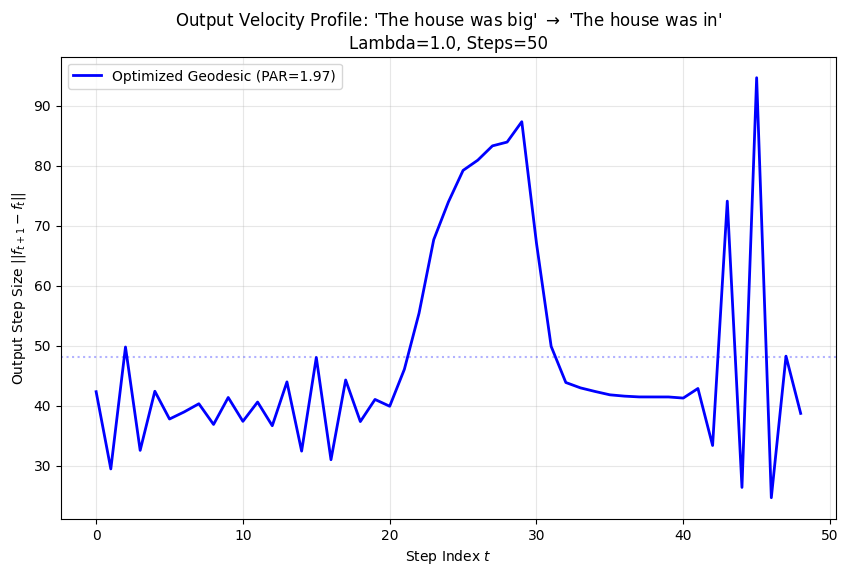

--------------------------------------------------
Initial Peak-to-Average Ratio:   9.72
Optimized Peak-to-Average Ratio: 1.97


In [ ]:
# --- 3. The Experiment Setup ---
# This one is only with output kinetic energy

prompt_a = "The house was big"
prompt_b = "The house was in"
n_steps = 50
lambda_val = 1.0
lr = 0.05
iterations = 1000

print(f"Optimizing path between: '{prompt_a}' and '{prompt_b}'")

# Get Endpoints
resid_a, _ = get_layer0_and_prefix(prompt_a)
resid_b, _ = get_layer0_and_prefix(prompt_b)

# Separate Prefix (Context) from Target (Last Token)
prefix_resid = resid_a[:, :-1, :]  # "The house was"
start_vec = resid_a[:, -1:, :]     # " big"
end_vec = resid_b[:, -1:, :]       # " large"

# Initialize Path with Slerp
initial_path = slerp_path(start_vec, end_vec, n_steps)

# Make it a trainable parameter
# We clone it so we can keep 'initial_path' for comparison later
optimized_path = nn.Parameter(initial_path.clone().detach())

# Optimizer
optimizer = optim.Adam([optimized_path], lr=lr)

# Logging
loss_history = []
velocity_history = []

# --- 4. The Optimization Loop ---

print("\nStarting Optimization...")
for i in range(iterations):
    optimizer.zero_grad()

    # 1. Forward Pass (Batch)
    current_logits = forward_batch_from_layer1(prefix_resid, optimized_path)

    # 2. Compute Energies (Cost Function)

    # Input Kinetic Energy: sum || P[t+1] - P[t] ||^2
    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    # Output Kinetic Energy: sum || f(P[t+1]) - f(P[t]) ||^2
    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    # Total Lagrangian
    # loss = energy_input + (lambda_val * energy_output)
    # we consider now only the output energy cost
    loss = energy_output
    # 3. Backward & Step
    loss.backward()
    optimizer.step()

    # 4. Boundary Constraint
    with torch.no_grad():
        # optimized_path[0] is [1, 768]
        # start_vec is [1, 1, 768] -> reshape to [1, 768]
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    loss_history.append(loss.item())
    if i % 20 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f} "
              f"(In: {energy_input.item():.2f}, Out: {energy_output.item():.2f})")

# --- 5. Analysis & Visualization ---

def compute_velocity_profile(path_tensor):
    """Computes ||f(t+1) - f(t)|| for the whole path."""
    with torch.no_grad():
        logits = forward_batch_from_layer1(prefix_resid, path_tensor)
        diffs = logits[1:] - logits[:-1]
        velocities = diffs.norm(dim=1).cpu().numpy()
    return velocities

print("\nComputing final profiles...")
vel_initial = compute_velocity_profile(initial_path)
vel_optimized = compute_velocity_profile(optimized_path)

# Metrics (Peak-to-Average Ratio)
par_initial = np.max(vel_initial) / np.mean(vel_initial)
par_optimized = np.max(vel_optimized) / np.mean(vel_optimized)

# Plotting
plt.figure(figsize=(10, 6))

#plt.plot(vel_initial, label=f'Initial Slerp (PAR={par_initial:.2f})',
#         color='red', linestyle='--', alpha=0.6)
plt.plot(vel_optimized, label=f'Optimized Geodesic (PAR={par_optimized:.2f})',
         color='blue', linewidth=2)

# Draw Mean lines
# plt.axhline(y=np.mean(vel_initial), color='red', linestyle=':', alpha=0.3)
plt.axhline(y=np.mean(vel_optimized), color='blue', linestyle=':', alpha=0.3)

plt.title(f"Output Velocity Profile: '{prompt_a}' $\\to$ '{prompt_b}'\n"
          f"Lambda={lambda_val}, Steps={n_steps}")
plt.xlabel("Step Index $t$")
plt.ylabel("Output Step Size $||f_{t+1} - f_t||$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Interpretation
print("-" * 50)
print(f"Initial Peak-to-Average Ratio:   {par_initial:.2f}")
print(f"Optimized Peak-to-Average Ratio: {par_optimized:.2f}")


Optimizing path between: 'The house was big' and 'The house was in'

Starting Optimization...
Iter 000: Loss 11880541.00 (In: 29.74, Out: 11880541.00)
Iter 020: Loss 3940370.50 (In: 479.44, Out: 3940370.50)
Iter 040: Loss 1479209.75 (In: 651.06, Out: 1479209.75)
Iter 060: Loss 998669.06 (In: 666.93, Out: 998669.06)
Iter 080: Loss 826502.50 (In: 653.82, Out: 826502.50)
Iter 100: Loss 737658.25 (In: 643.73, Out: 737658.25)
Iter 120: Loss 687617.44 (In: 637.56, Out: 687617.44)
Iter 140: Loss 621029.00 (In: 635.05, Out: 621029.00)
Iter 160: Loss 562129.75 (In: 634.54, Out: 562129.75)
Iter 180: Loss 474344.12 (In: 635.99, Out: 474344.12)

Computing final profiles...


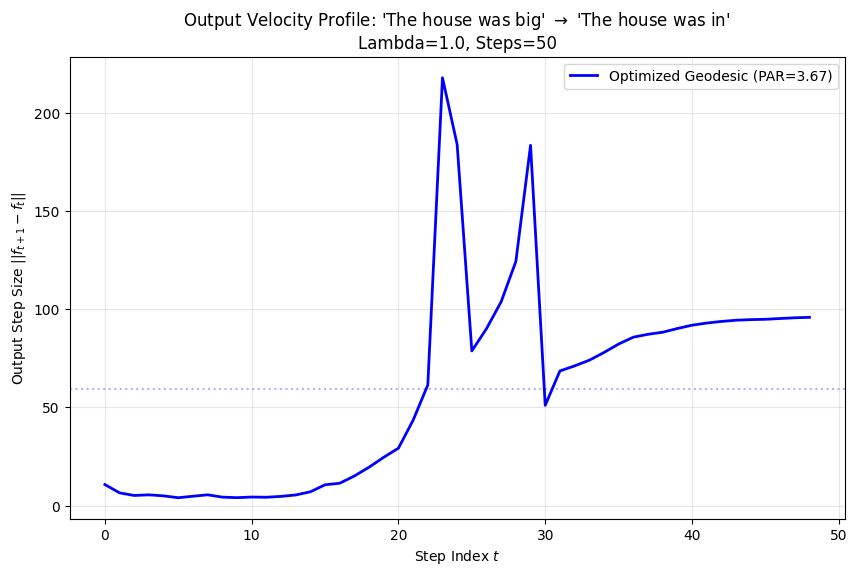

--------------------------------------------------
Initial Peak-to-Average Ratio:   9.72
Optimized Peak-to-Average Ratio: 3.67


In [ ]:
# --- 3. The Experiment Setup ---
# This one is only with output kinetic energy

prompt_a = "The house was big"
prompt_b = "The house was in"
n_steps = 50
lambda_val = 1.0
lr = 0.05
iterations = 200

print(f"Optimizing path between: '{prompt_a}' and '{prompt_b}'")

# Get Endpoints
resid_a, _ = get_layer0_and_prefix(prompt_a)
resid_b, _ = get_layer0_and_prefix(prompt_b)

# Separate Prefix (Context) from Target (Last Token)
prefix_resid = resid_a[:, :-1, :]  # "The house was"
start_vec = resid_a[:, -1:, :]     # " big"
end_vec = resid_b[:, -1:, :]       # " large"

# Initialize Path with Slerp
initial_path = slerp_path(start_vec, end_vec, n_steps)

# Make it a trainable parameter
# We clone it so we can keep 'initial_path' for comparison later
optimized_path = nn.Parameter(initial_path.clone().detach())

# Optimizer
optimizer = optim.Adam([optimized_path], lr=lr)

# Logging
loss_history = []
velocity_history = []

# --- 4. The Optimization Loop ---

print("\nStarting Optimization...")
for i in range(iterations):
    optimizer.zero_grad()

    # 1. Forward Pass (Batch)
    current_logits = forward_batch_from_layer1(prefix_resid, optimized_path)

    # 2. Compute Energies (Cost Function)

    # Input Kinetic Energy: sum || P[t+1] - P[t] ||^2
    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    # Output Kinetic Energy: sum || f(P[t+1]) - f(P[t]) ||^2
    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    # Total Lagrangian
    # loss = energy_input + (lambda_val * energy_output)
    # we consider now only the output energy cost
    loss = energy_output
    # 3. Backward & Step
    loss.backward()
    optimizer.step()

    # 4. Boundary Constraint
    with torch.no_grad():
        # optimized_path[0] is [1, 768]
        # start_vec is [1, 1, 768] -> reshape to [1, 768]
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    loss_history.append(loss.item())
    if i % 20 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f} "
              f"(In: {energy_input.item():.2f}, Out: {energy_output.item():.2f})")

# --- 5. Analysis & Visualization ---

def compute_velocity_profile(path_tensor):
    """Computes ||f(t+1) - f(t)|| for the whole path."""
    with torch.no_grad():
        logits = forward_batch_from_layer1(prefix_resid, path_tensor)
        diffs = logits[1:] - logits[:-1]
        velocities = diffs.norm(dim=1).cpu().numpy()
    return velocities

print("\nComputing final profiles...")
vel_initial = compute_velocity_profile(initial_path)
vel_optimized = compute_velocity_profile(optimized_path)

# Metrics (Peak-to-Average Ratio)
par_initial = np.max(vel_initial) / np.mean(vel_initial)
par_optimized = np.max(vel_optimized) / np.mean(vel_optimized)

# Plotting
plt.figure(figsize=(10, 6))

#plt.plot(vel_initial, label=f'Initial Slerp (PAR={par_initial:.2f})',
#         color='red', linestyle='--', alpha=0.6)
plt.plot(vel_optimized, label=f'Optimized Geodesic (PAR={par_optimized:.2f})',
         color='blue', linewidth=2)

# Draw Mean lines
# plt.axhline(y=np.mean(vel_initial), color='red', linestyle=':', alpha=0.3)
plt.axhline(y=np.mean(vel_optimized), color='blue', linestyle=':', alpha=0.3)

plt.title(f"Output Velocity Profile: '{prompt_a}' $\\to$ '{prompt_b}'\n"
          f"Lambda={lambda_val}, Steps={n_steps}")
plt.xlabel("Step Index $t$")
plt.ylabel("Output Step Size $||f_{t+1} - f_t||$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Interpretation
print("-" * 50)
print(f"Initial Peak-to-Average Ratio:   {par_initial:.2f}")
print(f"Optimized Peak-to-Average Ratio: {par_optimized:.2f}")


I ran the same optimization but now just with the second term, for 1000 iterations and 200 iterations. The loss gets significantly lower if you let it run longer, so as per our metric the path obtained with 1000 iterations is much better than the 200 iterations one. However, in terms of the plot we produce, the one for 200 iterations tells a much cleaner story: there's a messy path being take between steps 20 and 30, and stability before and after that. This corresponds fairly cleanly to the different regions story.

The plot for 1000 iterations is much messier! There's still something looking like a transition in steps 20-30, but there's plenty of wiggling otherwise. The absolute numbers are smaller though, hence it scores better in the metric.

STEP 1: Finding Boundary Distances
All prompts differ at token position: 0


Pair 1: 'He is a' ↔ 'She is a'
  Boundary location (t*): 18/50
  Boundary distance: 6.4658
  Total distance ||B-A||: 17.9606
  Peak-to-Average Ratio: 1.14

Pair 2: 'John is a' ↔ 'Jane is a'
  Boundary location (t*): 36/50
  Boundary distance: 19.4330
  Total distance ||B-A||: 26.9903
  Peak-to-Average Ratio: 1.16

Pair 3: 'Man is a' ↔ 'Woman is a'
  Boundary location (t*): 0/50
  Boundary distance: 0.0000
  Total distance ||B-A||: 26.9028
  Peak-to-Average Ratio: 1.74

SUMMARY
 pair_id  prompt_a   prompt_b  d_boundary  t_star      par
       1   He is a   She is a    6.465813      18 1.138580
       2 John is a  Jane is a   19.432984      36 1.162607
       3  Man is a Woman is a    0.000000       0 1.735494


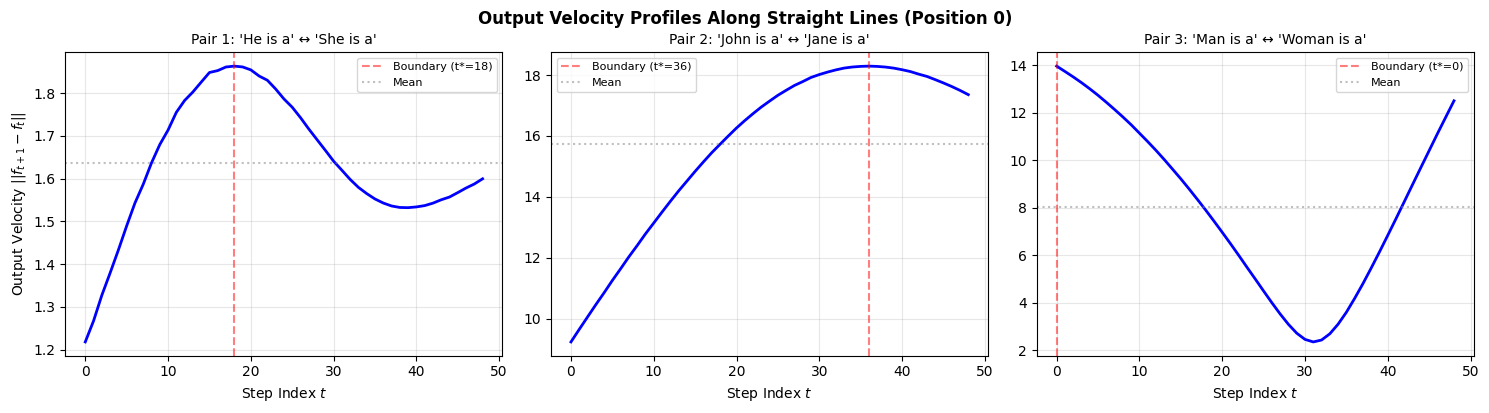

In [ ]:
# --- Step 1: Find Boundary Distances (CORRECTED) ---

import pandas as pd

# Define prompt pairs - all differ on FIRST token only
prompt_pairs = [
    ("He is a", "She is a"),
    ("John is a", "Jane is a"),
    ("Man is a", "Woman is a")
]

n_steps = 50  # Number of interpolation steps
DIFF_TOKEN_POS = 0  # All pairs differ on the first token

def compute_straight_line_boundary(prompt_a, prompt_b, diff_pos, n_steps=50):
    """
    Computes boundary distance for a straight line interpolation between two prompts
    that differ at position diff_pos.

    Args:
        prompt_a, prompt_b: The two prompts
        diff_pos: Token position where they differ (0-indexed)
        n_steps: Number of interpolation steps

    Returns:
        boundary_distance: Distance in activation space to the boundary
        boundary_location: Step index t* where boundary occurs
        velocities: Array of output velocities at each step
        total_distance: Total ||B - A|| distance
    """
    # Get Layer 0 outputs for both prompts
    resid_a, tokens_a = get_layer0_and_prefix(prompt_a)
    resid_b, tokens_b = get_layer0_and_prefix(prompt_b)

    # Verify prompts have same length and differ only at diff_pos
    assert resid_a.shape[1] == resid_b.shape[1], "Prompts must have same length"

    # Extract the differing token representation
    start_vec = resid_a[:, diff_pos:diff_pos+1, :]  # Shape: [1, 1, hidden_dim]
    end_vec = resid_b[:, diff_pos:diff_pos+1, :]    # Shape: [1, 1, hidden_dim]

    # Create context: all tokens except the one at diff_pos
    if diff_pos == 0:
        # If first token differs, context is everything after it
        prefix_resid = resid_a[:, 1:, :]
    elif diff_pos == resid_a.shape[1] - 1:
        # If last token differs, context is everything before it
        prefix_resid = resid_a[:, :-1, :]
    else:
        # If middle token differs, concatenate before and after
        prefix_resid = torch.cat([
            resid_a[:, :diff_pos, :],
            resid_a[:, diff_pos+1:, :]
        ], dim=1)

    # Create straight line interpolation
    # L_t = A + t * (B - A) for t = 0, ..., 1
    t_values = torch.linspace(0, 1, n_steps, device=device)

    # path_vectors will be [n_steps, 1, hidden_dim]
    path_vectors = torch.stack([
        start_vec + t * (end_vec - start_vec)
        for t in t_values
    ]).squeeze(1)  # Now [n_steps, 1, hidden_dim]

    # Reconstruct full sequences with interpolated token at diff_pos
    if diff_pos == 0:
        # Interpolated token first, then context
        prefix_batch = prefix_resid.expand(n_steps, -1, -1)
        full_sequences = torch.cat([path_vectors, prefix_batch], dim=1)
    elif diff_pos == resid_a.shape[1] - 1:
        # Context first, then interpolated token
        prefix_batch = prefix_resid.expand(n_steps, -1, -1)
        full_sequences = torch.cat([prefix_batch, path_vectors], dim=1)
    else:
        # Context before, interpolated token, context after
        prefix_before = resid_a[:, :diff_pos, :].expand(n_steps, -1, -1)
        prefix_after = resid_a[:, diff_pos+1:, :].expand(n_steps, -1, -1)
        full_sequences = torch.cat([prefix_before, path_vectors, prefix_after], dim=1)

    # Pass through remaining layers (1-11) to get logits
    with torch.no_grad():
        hidden = full_sequences
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)

        # Get logits for all token positions
        logits = model.lm_head(hidden[:, -1, :])  # Use last token for next-token prediction

        # Compute output velocity: ||f(t+1) - f(t)||
        diffs = logits[1:] - logits[:-1]
        velocities = diffs.norm(dim=1).cpu().numpy()

    # Find boundary location (argmax of velocity)
    t_star = np.argmax(velocities)

    # Compute distance in activation space to boundary
    # d_boundary = (t*/n_steps) * ||B - A||
    activation_distance = torch.norm(end_vec - start_vec).item()
    boundary_distance = (t_star / n_steps) * activation_distance

    return boundary_distance, t_star, velocities, activation_distance

# Run analysis for all pairs
results = []

print("=" * 60)
print("STEP 1: Finding Boundary Distances")
print("=" * 60)
print(f"All prompts differ at token position: {DIFF_TOKEN_POS}\n")

for i, (prompt_a, prompt_b) in enumerate(prompt_pairs, 1):
    print(f"\nPair {i}: '{prompt_a}' ↔ '{prompt_b}'")

    d_boundary, t_star, velocities, total_dist = compute_straight_line_boundary(
        prompt_a, prompt_b, DIFF_TOKEN_POS, n_steps
    )

    # Compute PAR (Peak-to-Average Ratio)
    par = np.max(velocities) / np.mean(velocities)

    results.append({
        'pair_id': i,
        'prompt_a': prompt_a,
        'prompt_b': prompt_b,
        'd_boundary': d_boundary,
        't_star': t_star,
        'total_distance': total_dist,
        'par': par,
        'max_velocity': np.max(velocities),
        'mean_velocity': np.mean(velocities)
    })

    print(f"  Boundary location (t*): {t_star}/{n_steps}")
    print(f"  Boundary distance: {d_boundary:.4f}")
    print(f"  Total distance ||B-A||: {total_dist:.4f}")
    print(f"  Peak-to-Average Ratio: {par:.2f}")

# Create summary DataFrame
df_results = pd.DataFrame(results)
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)
print(df_results[['pair_id', 'prompt_a', 'prompt_b', 'd_boundary', 't_star', 'par']].to_string(index=False))

# Visualize velocity profiles for all pairs
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, (prompt_a, prompt_b) in enumerate(prompt_pairs):
    _, t_star, velocities, _ = compute_straight_line_boundary(
        prompt_a, prompt_b, DIFF_TOKEN_POS, n_steps
    )

    ax = axes[i]
    ax.plot(velocities, linewidth=2, color='blue')
    ax.axvline(x=t_star, color='red', linestyle='--', alpha=0.5, label=f'Boundary (t*={t_star})')
    ax.axhline(y=np.mean(velocities), color='gray', linestyle=':', alpha=0.5, label='Mean')

    ax.set_title(f"Pair {i+1}: '{prompt_a}' ↔ '{prompt_b}'", fontsize=10)
    ax.set_xlabel("Step Index $t$")
    if i == 0:
        ax.set_ylabel("Output Velocity $||f_{t+1} - f_t||$")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle(f"Output Velocity Profiles Along Straight Lines (Position {DIFF_TOKEN_POS})",
             y=1.02, fontsize=12, fontweight='bold')
plt.show()

Interestingly all of the above have pretty low Peak-to-Average ratios, indicating that there isn't much of a boundary! The highest one is Man <-> Woman, with 1.74. Below I optimize the path, and find one with 1.26. I hesitate to call this a boundary. So it's all smooth? Interesting.

Things to test:
- Do these prompts produce different outputs? How different?
- Can we produce plots like the ones Stefan had produced? Relative distance in logit space (We compute relative distance (d) as a function of the recorded outputs (x) and the two endpoints (A and B) using the following equation:
d = ||x - A|| / (||x - A|| + ||x - B||)) versus the step index? I am interested in seeing how smooth they look in that picture.

Optimizing path between: 'Man is a' and 'Woman is a'

Starting Optimization...
Iter 000: Loss 3869.82 (In: 14.83, Out: 3854.99)
Iter 020: Loss 342336.47 (In: 27.38, Out: 342309.09)
Iter 040: Loss 35482.52 (In: 34.65, Out: 35447.88)
Iter 060: Loss 13632.70 (In: 35.78, Out: 13596.92)
Iter 080: Loss 7651.92 (In: 34.42, Out: 7617.50)
Iter 100: Loss 5763.20 (In: 32.82, Out: 5730.38)
Iter 120: Loss 4374.60 (In: 31.46, Out: 4343.13)
Iter 140: Loss 3360.80 (In: 30.34, Out: 3330.47)
Iter 160: Loss 2598.05 (In: 29.37, Out: 2568.68)
Iter 180: Loss 2038.42 (In: 28.52, Out: 2009.90)
Iter 200: Loss 1638.65 (In: 27.75, Out: 1610.90)
Iter 220: Loss 1360.24 (In: 27.05, Out: 1333.19)
Iter 240: Loss 1170.86 (In: 26.42, Out: 1144.45)
Iter 260: Loss 1044.78 (In: 25.84, Out: 1018.94)
Iter 280: Loss 962.39 (In: 25.31, Out: 937.08)
Iter 300: Loss 909.35 (In: 24.82, Out: 884.53)
Iter 320: Loss 875.57 (In: 24.38, Out: 851.20)
Iter 340: Loss 854.09 (In: 23.97, Out: 830.12)
Iter 360: Loss 840.31 (In: 23.59, Out: 

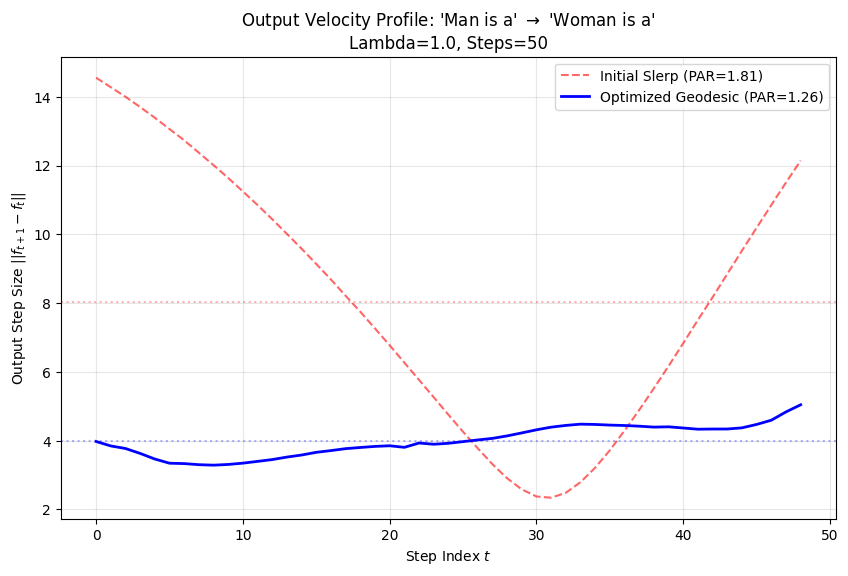

--------------------------------------------------
Initial Peak-to-Average Ratio:   1.81
Optimized Peak-to-Average Ratio: 1.26
Boundary location (t*): 48/49
Boundary distance: 26.3538
Total distance ||B-A||: 26.9028


In [ ]:
# --- Optimization Procedure for "He is a" vs "She is a" ---

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# --- 3. The Experiment Setup ---

prompt_a = "Man is a"
prompt_b = "Woman is a"
n_steps = 50
lambda_val = 1.0
lr = 0.02
iterations = 450

print(f"Optimizing path between: '{prompt_a}' and '{prompt_b}'")

# Get Endpoints
resid_a, _ = get_layer0_and_prefix(prompt_a)
resid_b, _ = get_layer0_and_prefix(prompt_b)

# These prompts differ on the FIRST token (position 0)
# Separate the differing token from the context
start_vec = resid_a[:, 0:1, :]     # "He"
end_vec = resid_b[:, 0:1, :]       # "She"
prefix_resid = resid_a[:, 1:, :]   # " is a" (everything after first token)

# Initialize Path with Slerp
initial_path = slerp_path(start_vec, end_vec, n_steps)

# Make it a trainable parameter
optimized_path = nn.Parameter(initial_path.clone().detach())

# Optimizer
optimizer = optim.Adam([optimized_path], lr=lr)

# Logging
loss_history = []

# --- 4. The Optimization Loop ---

print("\nStarting Optimization...")
for i in range(iterations):
    optimizer.zero_grad()

    # 1. Forward Pass (Batch)
    # We need to prepend the path vectors (first token) before the context
    # path_vectors: [n_steps, 1, hidden_dim]
    # prefix_resid: [1, seq_len-1, hidden_dim]

    # Expand prefix to match batch size
    prefix_batch = prefix_resid.expand(optimized_path.shape[0], -1, -1)

    # Concatenate: [n_steps, 1, hidden_dim] + [n_steps, seq_len-1, hidden_dim]
    # = [n_steps, seq_len, hidden_dim]
    full_sequences = torch.cat([optimized_path, prefix_batch], dim=1)

    # Pass through remaining layers
    hidden = full_sequences
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)

    # Get logits for last token position
    current_logits = model.lm_head(hidden[:, -1, :])

    # 2. Compute Energies (Cost Function)

    # Input Kinetic Energy: sum || P[t+1] - P[t] ||^2
    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    # Output Kinetic Energy: sum || f(P[t+1]) - f(P[t]) ||^2
    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    # Total Lagrangian
    loss = energy_input + (lambda_val * energy_output)

    # 3. Backward & Step
    loss.backward()
    optimizer.step()

    # 4. Boundary Constraint
    with torch.no_grad():
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    loss_history.append(loss.item())
    if i % 20 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f} "
              f"(In: {energy_input.item():.2f}, Out: {energy_output.item():.2f})")

# --- 5. Analysis & Visualization ---

def compute_velocity_profile_first_token(path_tensor, prefix):
    """Computes ||f(t+1) - f(t)|| for path where first token varies."""
    with torch.no_grad():
        # Expand prefix to match path batch size
        n_steps = path_tensor.shape[0]
        prefix_batch = prefix.expand(n_steps, -1, -1)

        # Concatenate path (first token) with prefix (rest)
        full_sequences = torch.cat([path_tensor, prefix_batch], dim=1)

        # Pass through remaining layers
        hidden = full_sequences
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)

        # Get logits for last token
        logits = model.lm_head(hidden[:, -1, :])

        # Compute velocities
        diffs = logits[1:] - logits[:-1]
        velocities = diffs.norm(dim=1).cpu().numpy()
    return velocities

print("\nComputing final profiles...")
vel_initial = compute_velocity_profile_first_token(initial_path, prefix_resid)
vel_optimized = compute_velocity_profile_first_token(optimized_path, prefix_resid)

# Metrics (Peak-to-Average Ratio)
par_initial = np.max(vel_initial) / np.mean(vel_initial)
par_optimized = np.max(vel_optimized) / np.mean(vel_optimized)

# Plotting
plt.figure(figsize=(10, 6))

plt.plot(vel_initial, label=f'Initial Slerp (PAR={par_initial:.2f})',
         color='red', linestyle='--', alpha=0.6)
plt.plot(vel_optimized, label=f'Optimized Geodesic (PAR={par_optimized:.2f})',
         color='blue', linewidth=2)

# Draw Mean lines
plt.axhline(y=np.mean(vel_initial), color='red', linestyle=':', alpha=0.3)
plt.axhline(y=np.mean(vel_optimized), color='blue', linestyle=':', alpha=0.3)

plt.title(f"Output Velocity Profile: '{prompt_a}' $\\to$ '{prompt_b}'\n"
          f"Lambda={lambda_val}, Steps={n_steps}")
plt.xlabel("Step Index $t$")
plt.ylabel("Output Step Size $||f_{t+1} - f_t||$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Interpretation
print("-" * 50)
print(f"Initial Peak-to-Average Ratio:   {par_initial:.2f}")
print(f"Optimized Peak-to-Average Ratio: {par_optimized:.2f}")

# Find boundary location
t_star = np.argmax(vel_optimized)
print(f"Boundary location (t*): {t_star}/{n_steps-1}")

# Compute boundary distance
activation_distance = torch.norm(end_vec - start_vec).item()
boundary_distance = (t_star / (n_steps - 1)) * activation_distance
print(f"Boundary distance: {boundary_distance:.4f}")
print(f"Total distance ||B-A||: {activation_distance:.4f}")


RELATIVE DISTANCE ANALYSIS


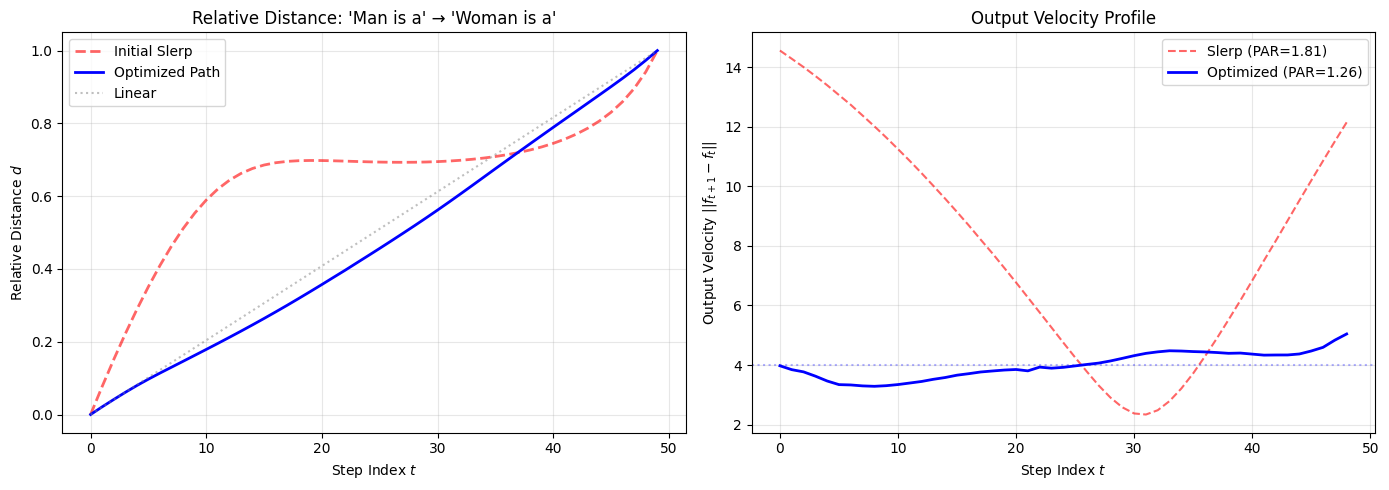


Relative distance at start: 0.0001 (should be ~0)
Relative distance at end: 0.9999 (should be ~1)

Deviation from linear:
  Mean absolute deviation: 0.0312

Derivative statistics:
  Mean: 0.0204
  Std: 0.0026
  Max: 0.0268
  Min: 0.0162

→ Very uniform transition, suggesting SMOOTH path (no plateaus)


In [ ]:
# --- 2. Relative Distance Plots (CORRECTED) ---

print("\n" + "=" * 60)
print("RELATIVE DISTANCE ANALYSIS")
print("=" * 60)

# Get endpoint logits by passing Layer 0 outputs through remaining layers (1-11)
with torch.no_grad():
    # For endpoint A (start_vec + prefix)
    full_seq_a = torch.cat([start_vec, prefix_resid], dim=1)
    hidden_a = full_seq_a
    for block in model.transformer.h[1:]:
        hidden_a = block(hidden_a)[0]
    hidden_a = model.transformer.ln_f(hidden_a)
    logits_a = model.lm_head(hidden_a[:, -1, :]).squeeze(0)

    # For endpoint B (end_vec + prefix)
    full_seq_b = torch.cat([end_vec, prefix_resid], dim=1)
    hidden_b = full_seq_b
    for block in model.transformer.h[1:]:
        hidden_b = block(hidden_b)[0]
    hidden_b = model.transformer.ln_f(hidden_b)
    logits_b = model.lm_head(hidden_b[:, -1, :]).squeeze(0)

# Compute relative distances for both slerp and optimized paths
rel_dist_initial = compute_relative_distance_profile(initial_path, prefix_resid, logits_a, logits_b)
rel_dist_optimized = compute_relative_distance_profile(optimized_path, prefix_resid, logits_a, logits_b)

# Plot relative distances
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Both paths
step_indices = np.arange(n_steps)
ax1.plot(step_indices, rel_dist_initial, label='Initial Slerp',
         color='red', linestyle='--', alpha=0.6, linewidth=2)
ax1.plot(step_indices, rel_dist_optimized, label='Optimized Path',
         color='blue', linewidth=2)

# Add diagonal reference line (perfectly linear transition)
ax1.plot(step_indices, np.linspace(0, 1, n_steps),
         color='gray', linestyle=':', alpha=0.5, label='Linear')

ax1.set_xlabel("Step Index $t$")
ax1.set_ylabel("Relative Distance $d$")
ax1.set_title(f"Relative Distance: '{prompt_a}' → '{prompt_b}'")
ax1.legend()
ax1.grid(True, alpha=0.3)
ax1.set_ylim(-0.05, 1.05)

# Plot 2: Velocity profile for comparison
ax2.plot(vel_initial, label=f'Slerp (PAR={par_initial:.2f})',
         color='red', linestyle='--', alpha=0.6)
ax2.plot(vel_optimized, label=f'Optimized (PAR={par_optimized:.2f})',
         color='blue', linewidth=2)
ax2.axhline(y=np.mean(vel_optimized), color='blue', linestyle=':', alpha=0.3)

ax2.set_xlabel("Step Index $t$")
ax2.set_ylabel("Output Velocity $||f_{t+1} - f_t||$")
ax2.set_title("Output Velocity Profile")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Analysis
print(f"\nRelative distance at start: {rel_dist_optimized[0]:.4f} (should be ~0)")
print(f"Relative distance at end: {rel_dist_optimized[-1]:.4f} (should be ~1)")
print(f"\nDeviation from linear:")
linear_ref = np.linspace(0, 1, n_steps)
deviation = np.mean(np.abs(rel_dist_optimized - linear_ref))
print(f"  Mean absolute deviation: {deviation:.4f}")

# Check for plateau structure
derivatives = np.abs(np.diff(rel_dist_optimized))
print(f"\nDerivative statistics:")
print(f"  Mean: {np.mean(derivatives):.4f}")
print(f"  Std: {np.std(derivatives):.4f}")
print(f"  Max: {np.max(derivatives):.4f}")
print(f"  Min: {np.min(derivatives):.4f}")

if np.std(derivatives) < 0.01:
    print("\n→ Very uniform transition, suggesting SMOOTH path (no plateaus)")
else:
    print("\n→ Non-uniform transition, suggesting possible boundary structure")

Our optimized path for Man is a -> Woman is a shows no boundary transition.

What if we do Lisbon is in vs Madrid is in? I guess there we strongly expect different output, namely Portugal vs Spain.

In [ ]:
# --- Test Case: Lisbon vs Madrid ---

prompt_a = "Lisbon is in"
prompt_b = "Madrid is in"
n_steps = 50
lambda_val = 1.0
lr = 0.05
iterations = 350

print("=" * 60)
print(f"Optimizing path between: '{prompt_a}' and '{prompt_b}'")
print("=" * 60)

# Get Endpoints
resid_a, _ = get_layer0_and_prefix(prompt_a)
resid_b, _ = get_layer0_and_prefix(prompt_b)

# These prompts differ on the FIRST token (Lisbon vs Madrid)
start_vec = resid_a[:, 0:1, :]     # "Lisbon"
end_vec = resid_b[:, 0:1, :]       # "Madrid"
prefix_resid = resid_a[:, 1:, :]   # " is in" (everything after first token)

# Initialize Path with Slerp
initial_path = slerp_path(start_vec, end_vec, n_steps)

# Make it a trainable parameter
optimized_path = nn.Parameter(initial_path.clone().detach())

# Optimizer
optimizer = optim.Adam([optimized_path], lr=lr)

# Logging
loss_history = []

# --- Optimization Loop ---

print("\nStarting Optimization...")
for i in range(iterations):
    optimizer.zero_grad()

    # Expand prefix to match batch size
    prefix_batch = prefix_resid.expand(optimized_path.shape[0], -1, -1)

    # Concatenate path with prefix
    full_sequences = torch.cat([optimized_path, prefix_batch], dim=1)

    # Pass through remaining layers
    hidden = full_sequences
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)

    # Get logits for last token position
    current_logits = model.lm_head(hidden[:, -1, :])

    # Compute Energies
    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    # Total Lagrangian
    loss = energy_input + (lambda_val * energy_output)

    # Backward & Step
    loss.backward()
    optimizer.step()

    # Boundary Constraint
    with torch.no_grad():
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    loss_history.append(loss.item())
    if i % 20 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f} "
              f"(In: {energy_input.item():.2f}, Out: {energy_output.item():.2f})")

# --- Analysis ---

print("\nComputing final profiles...")
vel_initial = compute_velocity_profile_first_token(initial_path, prefix_resid)
vel_optimized = compute_velocity_profile_first_token(optimized_path, prefix_resid)

# Metrics
par_initial = np.max(vel_initial) / np.mean(vel_initial)
par_optimized = np.max(vel_optimized) / np.mean(vel_optimized)

# Get endpoint logits
with torch.no_grad():
    # For endpoint A
    full_seq_a = torch.cat([start_vec, prefix_resid], dim=1)
    hidden_a = full_seq_a
    for block in model.transformer.h[1:]:
        hidden_a = block(hidden_a)[0]
    hidden_a = model.transformer.ln_f(hidden_a)
    logits_a = model.lm_head(hidden_a[:, -1, :]).squeeze(0)

    # For endpoint B
    full_seq_b = torch.cat([end_vec, prefix_resid], dim=1)
    hidden_b = full_seq_b
    for block in model.transformer.h[1:]:
        hidden_b = block(hidden_b)[0]
    hidden_b = model.transformer.ln_f(hidden_b)
    logits_b = model.lm_head(hidden_b[:, -1, :]).squeeze(0)

# Compute relative distances
rel_dist_initial = compute_relative_distance_profile(initial_path, prefix_resid, logits_a, logits_b)
rel_dist_optimized = compute_relative_distance_profile(optimized_path, prefix_resid, logits_a, logits_b)

# Plotting
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Velocity profiles
ax1 = axes[0, 0]
ax1.plot(vel_initial, label=f'Slerp (PAR={par_initial:.2f})',
         color='red', linestyle='--', alpha=0.6)
ax1.plot(vel_optimized, label=f'Optimized (PAR={par_optimized:.2f})',
         color='blue', linewidth=2)
ax1.axhline(y=np.mean(vel_optimized), color='blue', linestyle=':', alpha=0.3)
ax1.set_xlabel("Step Index $t$")
ax1.set_ylabel("Output Velocity $||f_{t+1} - f_t||$")
ax1.set_title("Output Velocity Profile")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Relative distances
ax2 = axes[0, 1]
step_indices = np.arange(n_steps)
ax2.plot(step_indices, rel_dist_initial, label='Slerp',
         color='red', linestyle='--', alpha=0.6, linewidth=2)
ax2.plot(step_indices, rel_dist_optimized, label='Optimized',
         color='blue', linewidth=2)
ax2.plot(step_indices, np.linspace(0, 1, n_steps),
         color='gray', linestyle=':', alpha=0.5, label='Linear')
ax2.set_xlabel("Step Index $t$")
ax2.set_ylabel("Relative Distance $d$")
ax2.set_title("Relative Distance Profile")
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(-0.05, 1.05)

# Plot 3: Check what the model predicts
ax3 = axes[1, 0]
print("\nTop predictions for each prompt:")
for prompt in [prompt_a, prompt_b]:
    top_k = get_top_k_tokens(prompt, k=5)
    print(f"\n'{prompt}':")
    token_labels = []
    for token, prob in top_k:
        print(f"  '{token}': {prob:.4f}")
        token_labels.append(f"'{token}' ({prob:.3f})")
ax3.text(0.1, 0.5, "See console output for top predictions",
         transform=ax3.transAxes, fontsize=12)
ax3.axis('off')

# Plot 4: Loss history
ax4 = axes[1, 1]
ax4.plot(loss_history, color='blue', linewidth=2)
ax4.set_xlabel("Iteration")
ax4.set_ylabel("Loss")
ax4.set_title("Optimization Loss")
ax4.grid(True, alpha=0.3)

plt.suptitle(f"Path Analysis: '{prompt_a}' → '{prompt_b}'",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Peak-to-Average Ratios:")
print(f"  Slerp:     {par_initial:.2f}")
print(f"  Optimized: {par_optimized:.2f}")

t_star = np.argmax(vel_optimized)
print(f"\nBoundary location: t* = {t_star}/{n_steps-1}")

derivatives = np.abs(np.diff(rel_dist_optimized))
print(f"\nRelative distance derivative statistics:")
print(f"  Mean: {np.mean(derivatives):.4f}")
print(f"  Std:  {np.std(derivatives):.4f}")
print(f"  Max:  {np.max(derivatives):.4f}")

if par_optimized > 2.0:
    print("\n→ HIGH PAR: Strong boundary detected!")
elif par_optimized > 1.5:
    print("\n→ MODERATE PAR: Possible boundary structure")
else:
    print("\n→ LOW PAR: Smooth transition, no clear boundary")

Optimizing path between: 'Lisbon is in' and 'Madrid is in'


NameError: name 'get_layer0_and_prefix' is not defined

Also no boundary between 'Lisbon is in' and 'Spain is in'. Further, the plots show a few different things:
1. PAR is not a good metric for whether there is a boundary - the relative distance plot is much better for that. I guess because velocity is an 'instantaneous' metric? This plot has a peak, but I guess because it's very short lived it doesn't translate to a lot of distance traversed, and so it doesn't really reflect on the relative distance profile.
2. More broadly, does this suggest that we should be optimizing differently in our search for paths? Let me think. We want to find paths where the output vs activation response is roughly linear, right? I think so, roughly. But even though this PAR metric is not good, the paths we are finding are quite linear - the one we have here, despite its poor PAR metric actually tracks the line very closely. So perhaps there's no issue with the optimization, just the PAR metric?

Further, GPT-2 does not seem to 'know' that Lisbon and Madrid are in Portugal and Spain, respectively - or at least it does not deem it important to predict those countries as the next token :-). Let's try to find prompts for which GPT-2 actually predicts different tokens, and preferably for which said predictions indicate that it has some concepts stored.

Testing: 'The capital of Spain is' vs 'The capital of France is'

Top predictions:

'The capital of Spain is':
  ' Madrid': 0.1050
  ' the': 0.0950
  ' Barcelona': 0.0703
  ' a': 0.0401
  ' now': 0.0282

'The capital of France is':
  ' the': 0.0846
  ' now': 0.0479
  ' a': 0.0462
  ' France': 0.0324
  ' Paris': 0.0322

Sequence length: 5 tokens

Tokens:
A: ['The', 'Ġcapital', 'Ġof', 'ĠSpain', 'Ġis']
B: ['The', 'Ġcapital', 'Ġof', 'ĠFrance', 'Ġis']

Interpolating at position 3
Context before: 3 tokens
Context after: 1 tokens

Optimizing path...
Iter 000: Loss 3265.27
Iter 050: Loss 21113.95
Iter 100: Loss 6878.69
Iter 150: Loss 3493.79


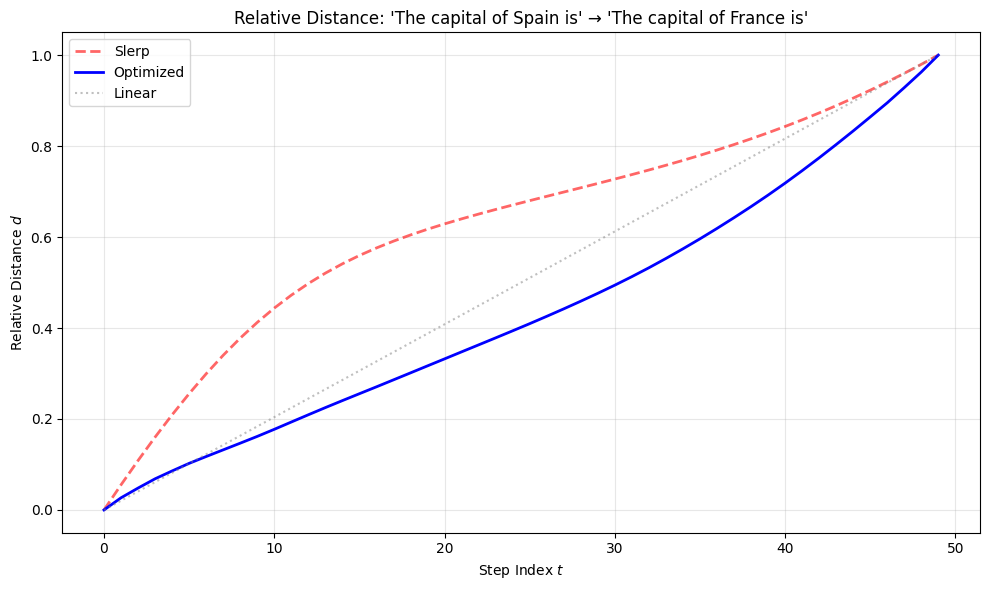


ANALYSIS
Start: d=0.0000 (should be ~0)
End: d=1.0000 (should be ~1)

Mean deviation from linear: 0.0650
→ Slightly non-linear - possible weak boundary


In [ ]:
# --- Test Case: Spain vs France Capitals ---

prompt_a = "The capital of Spain is"
prompt_b = "The capital of France is"
n_steps = 50
lambda_val = 1.0
lr = 0.05
iterations = 200

print("=" * 60)
print(f"Testing: '{prompt_a}' vs '{prompt_b}'")
print("=" * 60)

# First, check what GPT-2 predicts
print("\nTop predictions:")
for prompt in [prompt_a, prompt_b]:
    top_k = get_top_k_tokens(prompt, k=5)
    print(f"\n'{prompt}':")
    for token, prob in top_k:
        print(f"  '{token}': {prob:.4f}")

# Get Layer 0 outputs
resid_a, tokens_a = get_layer0_and_prefix(prompt_a)
resid_b, tokens_b = get_layer0_and_prefix(prompt_b)

print(f"\nSequence length: {resid_a.shape[1]} tokens")

# Find which token position differs
# Assuming they differ at position 3 ("Spain" vs "France")
# But let's verify by checking which positions are different
print("\nTokens:")
print(f"A: {tokenizer.convert_ids_to_tokens(tokens_a[0])}")
print(f"B: {tokenizer.convert_ids_to_tokens(tokens_b[0])}")

# For now, assume they differ at position 3
DIFF_POS = 3

start_vec = resid_a[:, DIFF_POS:DIFF_POS+1, :]
end_vec = resid_b[:, DIFF_POS:DIFF_POS+1, :]

# Context = everything except the differing token
prefix_before = resid_a[:, :DIFF_POS, :]
prefix_after = resid_a[:, DIFF_POS+1:, :]

print(f"\nInterpolating at position {DIFF_POS}")
print(f"Context before: {prefix_before.shape[1]} tokens")
print(f"Context after: {prefix_after.shape[1]} tokens")

# Initialize Path with Slerp
initial_path = slerp_path(start_vec, end_vec, n_steps)
optimized_path = nn.Parameter(initial_path.clone().detach())
optimizer = optim.Adam([optimized_path], lr=lr)

# --- Optimization Loop ---

print("\nOptimizing path...")
for i in range(iterations):
    optimizer.zero_grad()

    # Reconstruct full sequences with interpolated token
    prefix_before_batch = prefix_before.expand(optimized_path.shape[0], -1, -1)
    prefix_after_batch = prefix_after.expand(optimized_path.shape[0], -1, -1)
    full_sequences = torch.cat([prefix_before_batch, optimized_path, prefix_after_batch], dim=1)

    # Pass through remaining layers
    hidden = full_sequences
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    current_logits = model.lm_head(hidden[:, -1, :])

    # Compute Energies
    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    loss = energy_input + (lambda_val * energy_output)

    loss.backward()
    optimizer.step()

    with torch.no_grad():
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    if i % 50 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f}")

# --- Get Endpoint Logits ---

with torch.no_grad():
    # Endpoint A
    full_seq_a = torch.cat([prefix_before, start_vec, prefix_after], dim=1)
    hidden_a = full_seq_a
    for block in model.transformer.h[1:]:
        hidden_a = block(hidden_a)[0]
    hidden_a = model.transformer.ln_f(hidden_a)
    logits_a = model.lm_head(hidden_a[:, -1, :]).squeeze(0)

    # Endpoint B
    full_seq_b = torch.cat([prefix_before, end_vec, prefix_after], dim=1)
    hidden_b = full_seq_b
    for block in model.transformer.h[1:]:
        hidden_b = block(hidden_b)[0]
    hidden_b = model.transformer.ln_f(hidden_b)
    logits_b = model.lm_head(hidden_b[:, -1, :]).squeeze(0)

# --- Compute Relative Distances ---

def compute_relative_distance_midtoken(path_tensor, prefix_before, prefix_after, logits_a, logits_b):
    """For paths where a middle token varies."""
    with torch.no_grad():
        n_steps = path_tensor.shape[0]
        prefix_before_batch = prefix_before.expand(n_steps, -1, -1)
        prefix_after_batch = prefix_after.expand(n_steps, -1, -1)
        full_sequences = torch.cat([prefix_before_batch, path_tensor, prefix_after_batch], dim=1)

        hidden = full_sequences
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits_path = model.lm_head(hidden[:, -1, :])

        relative_distances = []
        for logits_x in logits_path:
            dist_to_a = torch.norm(logits_x - logits_a).item()
            dist_to_b = torch.norm(logits_x - logits_b).item()
            rel_dist = dist_to_a / (dist_to_a + dist_to_b)
            relative_distances.append(rel_dist)

        return np.array(relative_distances)

rel_dist_initial = compute_relative_distance_midtoken(initial_path, prefix_before, prefix_after, logits_a, logits_b)
rel_dist_optimized = compute_relative_distance_midtoken(optimized_path, prefix_before, prefix_after, logits_a, logits_b)

# --- Plot ---

plt.figure(figsize=(10, 6))

step_indices = np.arange(n_steps)
plt.plot(step_indices, rel_dist_initial, label='Slerp',
         color='red', linestyle='--', alpha=0.6, linewidth=2)
plt.plot(step_indices, rel_dist_optimized, label='Optimized',
         color='blue', linewidth=2)
plt.plot(step_indices, np.linspace(0, 1, n_steps),
         color='gray', linestyle=':', alpha=0.5, label='Linear')

plt.xlabel("Step Index $t$")
plt.ylabel("Relative Distance $d$")
plt.title(f"Relative Distance: '{prompt_a}' → '{prompt_b}'")
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

# Analysis
print("\n" + "=" * 60)
print("ANALYSIS")
print("=" * 60)
print(f"Start: d={rel_dist_optimized[0]:.4f} (should be ~0)")
print(f"End: d={rel_dist_optimized[-1]:.4f} (should be ~1)")

linear_ref = np.linspace(0, 1, n_steps)
deviation = np.mean(np.abs(rel_dist_optimized - linear_ref))
print(f"\nMean deviation from linear: {deviation:.4f}")

# Check for plateau structure
if deviation < 0.05:
    print("→ Very close to linear - SMOOTH transition, no boundary")
elif deviation < 0.1:
    print("→ Slightly non-linear - possible weak boundary")
else:
    print("→ Significantly non-linear - BOUNDARY present")

GPT-2 small is apparently not great at factual recall, which is making this challenging :-) Stefan anyway performed his experiments on GPT-2 large, so let me do the same.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from transformers import GPT2LMHeadModel, GPT2Tokenizer

# --- Load GPT-2 Large ---

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Load GPT-2 Large
model = GPT2LMHeadModel.from_pretrained('gpt2-large').to(device)
tokenizer = GPT2Tokenizer.from_pretrained('gpt2-large')
model.eval()

# Freeze model
for param in model.parameters():
    param.requires_grad = False

print(f"Model loaded: {model.config.model_type}")
print(f"Number of layers: {model.config.n_layer}")
print(f"Hidden size: {model.config.n_embd}")
print(f"Number of parameters: {model.num_parameters():,}")

Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.25G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Model loaded: gpt2
Number of layers: 36
Hidden size: 1280
Number of parameters: 774,030,080


In [ ]:
# --- Test Case: Spain vs France Capitals ---

prompt_a = "The capital of Spain is"
prompt_b = "The capital of France is"
n_steps = 50
lambda_val = 1.0
lr = 0.05
iterations = 200

print("=" * 60)
print(f"Testing: '{prompt_a}' vs '{prompt_b}'")
print("=" * 60)

# First, check what GPT-2 Large predicts
print("\nTop predictions:")
for prompt in [prompt_a, prompt_b]:
    top_k = get_top_k_tokens(prompt, k=5)
    print(f"\n'{prompt}':")
    for token, prob in top_k:
        print(f"  '{token}': {prob:.4f}")

# Get Layer 0 outputs
resid_a, tokens_a = get_layer0_and_prefix(prompt_a)
resid_b, tokens_b = get_layer0_and_prefix(prompt_b)

print(f"\nSequence length: {resid_a.shape[1]} tokens")
print("\nTokens:")
print(f"A: {tokenizer.convert_ids_to_tokens(tokens_a[0])}")
print(f"B: {tokenizer.convert_ids_to_tokens(tokens_b[0])}")

# They should differ at position 3 ("Spain" vs "France")
DIFF_POS = 3

start_vec = resid_a[:, DIFF_POS:DIFF_POS+1, :]
end_vec = resid_b[:, DIFF_POS:DIFF_POS+1, :]

prefix_before = resid_a[:, :DIFF_POS, :]
prefix_after = resid_a[:, DIFF_POS+1:, :]

print(f"\nInterpolating at position {DIFF_POS}")

# Initialize Path
initial_path = slerp_path(start_vec, end_vec, n_steps)
optimized_path = nn.Parameter(initial_path.clone().detach())
optimizer = optim.Adam([optimized_path], lr=lr)

# --- Optimization Loop ---

print("\nOptimizing path...")
for i in range(iterations):
    optimizer.zero_grad()

    prefix_before_batch = prefix_before.expand(optimized_path.shape[0], -1, -1)
    prefix_after_batch = prefix_after.expand(optimized_path.shape[0], -1, -1)
    full_sequences = torch.cat([prefix_before_batch, optimized_path, prefix_after_batch], dim=1)

    hidden = full_sequences
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    current_logits = model.lm_head(hidden[:, -1, :])

    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    loss = energy_input + (lambda_val * energy_output)

    loss.backward()
    optimizer.step()

    with torch.no_grad():
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    if i % 50 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f}")

# --- Get Endpoint Logits ---

with torch.no_grad():
    full_seq_a = torch.cat([prefix_before, start_vec, prefix_after], dim=1)
    hidden_a = full_seq_a
    for block in model.transformer.h[1:]:
        hidden_a = block(hidden_a)[0]
    hidden_a = model.transformer.ln_f(hidden_a)
    logits_a = model.lm_head(hidden_a[:, -1, :]).squeeze(0)

    full_seq_b = torch.cat([prefix_before, end_vec, prefix_after], dim=1)
    hidden_b = full_seq_b
    for block in model.transformer.h[1:]:
        hidden_b = block(hidden_b)[0]
    hidden_b = model.transformer.ln_f(hidden_b)
    logits_b = model.lm_head(hidden_b[:, -1, :]).squeeze(0)

# --- Compute Relative Distances ---

rel_dist_initial = compute_relative_distance_midtoken(initial_path, prefix_before, prefix_after, logits_a, logits_b)
rel_dist_optimized = compute_relative_distance_midtoken(optimized_path, prefix_before, prefix_after, logits_a, logits_b)

# --- Plot ---

plt.figure(figsize=(10, 6))

step_indices = np.arange(n_steps)
plt.plot(step_indices, rel_dist_initial, label='Slerp',
         color='red', linestyle='--', alpha=0.6, linewidth=2)
plt.plot(step_indices, rel_dist_optimized, label='Optimized',
         color='blue', linewidth=2)
plt.plot(step_indices, np.linspace(0, 1, n_steps),
         color='gray', linestyle=':', alpha=0.5, label='Linear')

plt.xlabel("Step Index $t$")
plt.ylabel("Relative Distance $d$")
plt.title(f"Relative Distance: '{prompt_a}' → '{prompt_b}' (GPT-2 Large)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

# Analysis
print("\n" + "=" * 60)
print("ANALYSIS")
print("=" * 60)
print(f"Start: d={rel_dist_optimized[0]:.4f}")
print(f"End: d={rel_dist_optimized[-1]:.4f}")

linear_ref = np.linspace(0, 1, n_steps)
deviation = np.mean(np.abs(rel_dist_optimized - linear_ref))
print(f"\nMean deviation from linear: {deviation:.4f}")

if deviation < 0.05:
    print("→ SMOOTH transition, no boundary")
elif deviation < 0.1:
    print("→ Possible weak boundary")
else:
    print("→ BOUNDARY present")

Testing: 'The capital of Spain is' vs 'The capital of France is'

Top predictions:


NameError: name 'get_top_k_tokens' is not defined

Mean deviation from linear: 0.0093
The slerp line starts to look boundary-like, but our optimization finds something extremely close to linear! Further evidence of our optimization being useful, which is nice.

But then this begs the question: what the hell can we ask GPT -2 Large such that it has strong factual recall. Note the following:

Top predictions:

'The capital of Spain is':
  ' Madrid': 0.1476
  ' the': 0.0967
  ' Barcelona': 0.0856
  ' a': 0.0734
  ' also': 0.0482

'The capital of France is':
  ' the': 0.0970
  ' Paris': 0.0721
  ' a': 0.0696
  ' also': 0.0403
  ' located': 0.0395

It's still fairly confused!

In [ ]:
# Test various prompt types for confidence

test_prompts = [
    # Opposites (might be high confidence)
    "The opposite of hot is",
    "The opposite of cold is",

    # Strong collocations
    "peanut butter and",
    "fish and",

    # Grammatical constraints
    "I am a boy. She is a",
    "I am a girl. He is a",

    # Stefan's original
    "The house was big",
    "The house was in",

    # Simple math
    "1 + 1 =",
    "2 + 2 =",

    # Code syntax
    "In Python: print(",
    "In JavaScript: console.log(",
]

print("=" * 60)
print("TESTING FOR HIGH-CONFIDENCE PREDICTIONS")
print("=" * 60)

for prompt in test_prompts:
    top_k = get_top_k_tokens(prompt, k=3)
    top_prob = top_k[0][1]

    print(f"\n'{prompt}'")
    for token, prob in top_k:
        print(f"  '{token}': {prob:.4f}")

    if top_prob > 0.3:
        print(f"  → HIGH confidence ({top_prob:.2%})")

TESTING FOR HIGH-CONFIDENCE PREDICTIONS

'The opposite of hot is'
  ' cold': 0.7914
  ' not': 0.0478
  ' cool': 0.0433
  → HIGH confidence (79.14%)

'The opposite of cold is'
  ' hot': 0.3200
  ' warm': 0.1344
  ' heat': 0.1036
  → HIGH confidence (32.00%)

'peanut butter and'
  ' jelly': 0.4634
  ' chocolate': 0.0847
  ' banana': 0.0710
  → HIGH confidence (46.34%)

'fish and'
  ' other': 0.0538
  ' the': 0.0420
  ' fish': 0.0277

'I am a boy. She is a'
  ' girl': 0.5763
  ' woman': 0.2141
  ' boy': 0.0327
  → HIGH confidence (57.63%)

'I am a girl. He is a'
  ' boy': 0.4198
  ' man': 0.3395
  ' guy': 0.0787
  → HIGH confidence (41.98%)

'The house was big'
  ' enough': 0.2941
  ',': 0.2395
  ' and': 0.1988

'The house was in'
  ' a': 0.2415
  ' the': 0.1579
  ' an': 0.0379

'1 + 1 ='
  ' 2': 0.2411
  ' 3': 0.1716
  ' 4': 0.0986

'2 + 2 ='
  ' 5': 0.1694
  ' 4': 0.1640
  ' 6': 0.1506

'In Python: print('
  'str': 0.0438
  'x': 0.0232
  ' "': 0.0227

'In JavaScript: console.log('
  'th

Quite high confidence on hot/cold:
'The opposite of hot is'
  ' cold': 0.7914
  ' not': 0.0478
  ' cool': 0.0433
  → HIGH confidence (79.14%)

'The opposite of cold is'
  ' hot': 0.3200
  ' warm': 0.1344
  ' heat': 0.1036
  → HIGH confidence (32.00%)
  Only 32% for 'hot' being the opposite of 'cold', but note that 'warm' and 'heat' are synonyms and bring it up to ~55. So let's try this pair of prompts.

Testing: 'The opposite of hot is' vs 'The opposite of cold is'

Top predictions:

'The opposite of hot is':
  ' cold': 0.7914
  ' not': 0.0478
  ' cool': 0.0433
  ' hot': 0.0068
  ' freezing': 0.0045

'The opposite of cold is':
  ' hot': 0.3200
  ' warm': 0.1344
  ' heat': 0.1036
  ' warmth': 0.0785
  ' not': 0.0425

Sequence length: 5 tokens

Tokens:
A: ['The', 'Ġopposite', 'Ġof', 'Ġhot', 'Ġis']
B: ['The', 'Ġopposite', 'Ġof', 'Ġcold', 'Ġis']

Interpolating at position 3
Context before: 3 tokens
Context after: 1 tokens

Optimizing path...
Iter 000: Loss 4173.29
Iter 050: Loss 3237.11
Iter 100: Loss 2563.45
Iter 150: Loss 2417.28


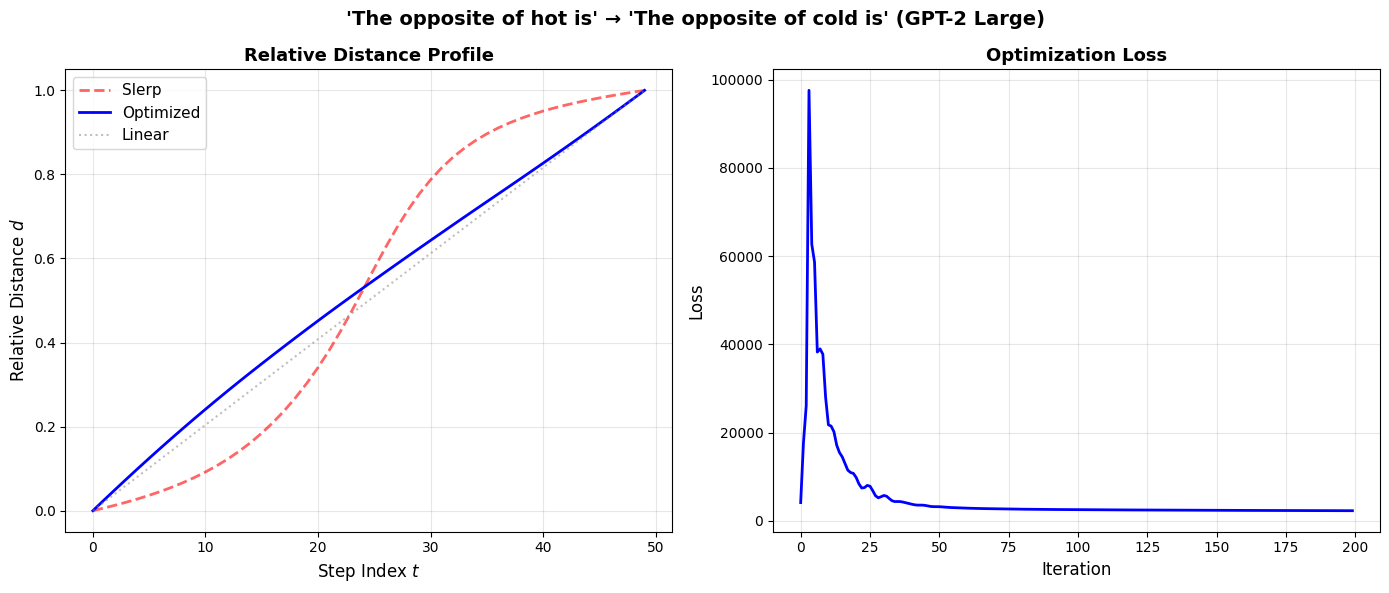


ANALYSIS
Start: d=0.0000 (should be ~0)
End: d=1.0000 (should be ~1)

Deviation from linear:
  Mean: 0.0254
  Max:  0.0442

Derivative statistics (measure of uniformity):
  Mean: 0.0204
  Std:  0.0022
  Max:  0.0255
  Min:  0.0182

Conclusion:
→ SMOOTH transition - no boundary detected
   The optimized path is nearly linear


In [ ]:
# --- Test Case: Hot vs Cold ---

prompt_a = "The opposite of hot is"
prompt_b = "The opposite of cold is"
n_steps = 50
lambda_val = 1.0
lr = 0.05
iterations = 200

print("=" * 60)
print(f"Testing: '{prompt_a}' vs '{prompt_b}'")
print("=" * 60)

# First, check what GPT-2 Large predicts
print("\nTop predictions:")
for prompt in [prompt_a, prompt_b]:
    top_k = get_top_k_tokens(prompt, k=5)
    print(f"\n'{prompt}':")
    for token, prob in top_k:
        print(f"  '{token}': {prob:.4f}")

# Get Layer 0 outputs
resid_a, tokens_a = get_layer0_and_prefix(prompt_a)
resid_b, tokens_b = get_layer0_and_prefix(prompt_b)

print(f"\nSequence length: {resid_a.shape[1]} tokens")
print("\nTokens:")
print(f"A: {tokenizer.convert_ids_to_tokens(tokens_a[0])}")
print(f"B: {tokenizer.convert_ids_to_tokens(tokens_b[0])}")

# They differ at position 3 ("hot" vs "cold")
DIFF_POS = 3

start_vec = resid_a[:, DIFF_POS:DIFF_POS+1, :]
end_vec = resid_b[:, DIFF_POS:DIFF_POS+1, :]

prefix_before = resid_a[:, :DIFF_POS, :]
prefix_after = resid_a[:, DIFF_POS+1:, :]

print(f"\nInterpolating at position {DIFF_POS}")
print(f"Context before: {prefix_before.shape[1]} tokens")
print(f"Context after: {prefix_after.shape[1]} tokens")

# Initialize Path
initial_path = slerp_path(start_vec, end_vec, n_steps)
optimized_path = nn.Parameter(initial_path.clone().detach())
optimizer = optim.Adam([optimized_path], lr=lr)

# --- Optimization Loop ---

print("\nOptimizing path...")
loss_history = []

for i in range(iterations):
    optimizer.zero_grad()

    prefix_before_batch = prefix_before.expand(optimized_path.shape[0], -1, -1)
    prefix_after_batch = prefix_after.expand(optimized_path.shape[0], -1, -1)
    full_sequences = torch.cat([prefix_before_batch, optimized_path, prefix_after_batch], dim=1)

    hidden = full_sequences
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    current_logits = model.lm_head(hidden[:, -1, :])

    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    loss = energy_input + (lambda_val * energy_output)

    loss.backward()
    optimizer.step()

    with torch.no_grad():
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    loss_history.append(loss.item())

    if i % 50 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f}")

# --- Get Endpoint Logits ---

with torch.no_grad():
    full_seq_a = torch.cat([prefix_before, start_vec, prefix_after], dim=1)
    hidden_a = full_seq_a
    for block in model.transformer.h[1:]:
        hidden_a = block(hidden_a)[0]
    hidden_a = model.transformer.ln_f(hidden_a)
    logits_a = model.lm_head(hidden_a[:, -1, :]).squeeze(0)

    full_seq_b = torch.cat([prefix_before, end_vec, prefix_after], dim=1)
    hidden_b = full_seq_b
    for block in model.transformer.h[1:]:
        hidden_b = block(hidden_b)[0]
    hidden_b = model.transformer.ln_f(hidden_b)
    logits_b = model.lm_head(hidden_b[:, -1, :]).squeeze(0)

# --- Compute Relative Distances ---

rel_dist_initial = compute_relative_distance_midtoken(initial_path, prefix_before, prefix_after, logits_a, logits_b)
rel_dist_optimized = compute_relative_distance_midtoken(optimized_path, prefix_before, prefix_after, logits_a, logits_b)

# --- Plot ---

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Relative Distance
step_indices = np.arange(n_steps)
ax1.plot(step_indices, rel_dist_initial, label='Slerp',
         color='red', linestyle='--', alpha=0.6, linewidth=2)
ax1.plot(step_indices, rel_dist_optimized, label='Optimized',
         color='blue', linewidth=2)
ax1.plot(step_indices, np.linspace(0, 1, n_steps),
         color='gray', linestyle=':', alpha=0.5, label='Linear')

ax1.set_xlabel("Step Index $t$", fontsize=12)
ax1.set_ylabel("Relative Distance $d$", fontsize=12)
ax1.set_title(f"Relative Distance Profile", fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(-0.05, 1.05)

# Plot 2: Loss History
ax2.plot(loss_history, color='blue', linewidth=2)
ax2.set_xlabel("Iteration", fontsize=12)
ax2.set_ylabel("Loss", fontsize=12)
ax2.set_title("Optimization Loss", fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.suptitle(f"'{prompt_a}' → '{prompt_b}' (GPT-2 Large)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Analysis ---

print("\n" + "=" * 60)
print("ANALYSIS")
print("=" * 60)
print(f"Start: d={rel_dist_optimized[0]:.4f} (should be ~0)")
print(f"End: d={rel_dist_optimized[-1]:.4f} (should be ~1)")

linear_ref = np.linspace(0, 1, n_steps)
deviation = np.mean(np.abs(rel_dist_optimized - linear_ref))
max_deviation = np.max(np.abs(rel_dist_optimized - linear_ref))

print(f"\nDeviation from linear:")
print(f"  Mean: {deviation:.4f}")
print(f"  Max:  {max_deviation:.4f}")

# Check for plateau structure by looking at derivatives
derivatives = np.abs(np.diff(rel_dist_optimized))
print(f"\nDerivative statistics (measure of uniformity):")
print(f"  Mean: {np.mean(derivatives):.4f}")
print(f"  Std:  {np.std(derivatives):.4f}")
print(f"  Max:  {np.max(derivatives):.4f}")
print(f"  Min:  {np.min(derivatives):.4f}")

# Simple classification
print("\nConclusion:")
if max_deviation < 0.1:
    print("→ SMOOTH transition - no boundary detected")
    print("   The optimized path is nearly linear")
elif max_deviation < 0.2:
    print("→ WEAK boundary structure detected")
    print("   Some deviation from linearity")
else:
    print("→ STRONG boundary detected!")
    print("   Significant plateau structure present")

With the slerp path we do get something that looks like a boundary, although it is not super sharp. This is however not the case for our optimized path! We in fact get something very close to linear...

Hm... Are we actually 'invalidating' Stefan's results by showing activation plateaus do not exist? Or at least that they are much rarer than we thought? I mean, I do think I also observed it for 'The house was big' vs 'The house was in', but that was with GPT-2 small. Maybe we should also try with GPT-2 Large to be sure.

Testing Stefan's original: 'The house was big' vs 'The house was in'

Top predictions:

'The house was big':
  ' enough': 0.2941
  ',': 0.2395
  ' and': 0.1988
  '.': 0.0834
  ' but': 0.0262

'The house was in':
  ' a': 0.2415
  ' the': 0.1579
  ' an': 0.0379
  ' good': 0.0364
  ' dis': 0.0319

Sequence length: 4 tokens

Tokens:
A: ['The', 'Ġhouse', 'Ġwas', 'Ġbig']
B: ['The', 'Ġhouse', 'Ġwas', 'Ġin']

Interpolating at LAST token position
Context (prefix): 3 tokens

Optimizing path...
Iter 000: Loss 321993.72
Iter 050: Loss 854580.88
Iter 100: Loss 396354.75
Iter 150: Loss 199644.94
Iter 200: Loss 139928.52
Iter 250: Loss 110869.58
Iter 300: Loss 84204.10
Iter 350: Loss 57375.44
Iter 400: Loss 44025.83
Iter 450: Loss 37033.55
Iter 500: Loss 32864.90
Iter 550: Loss 29179.49


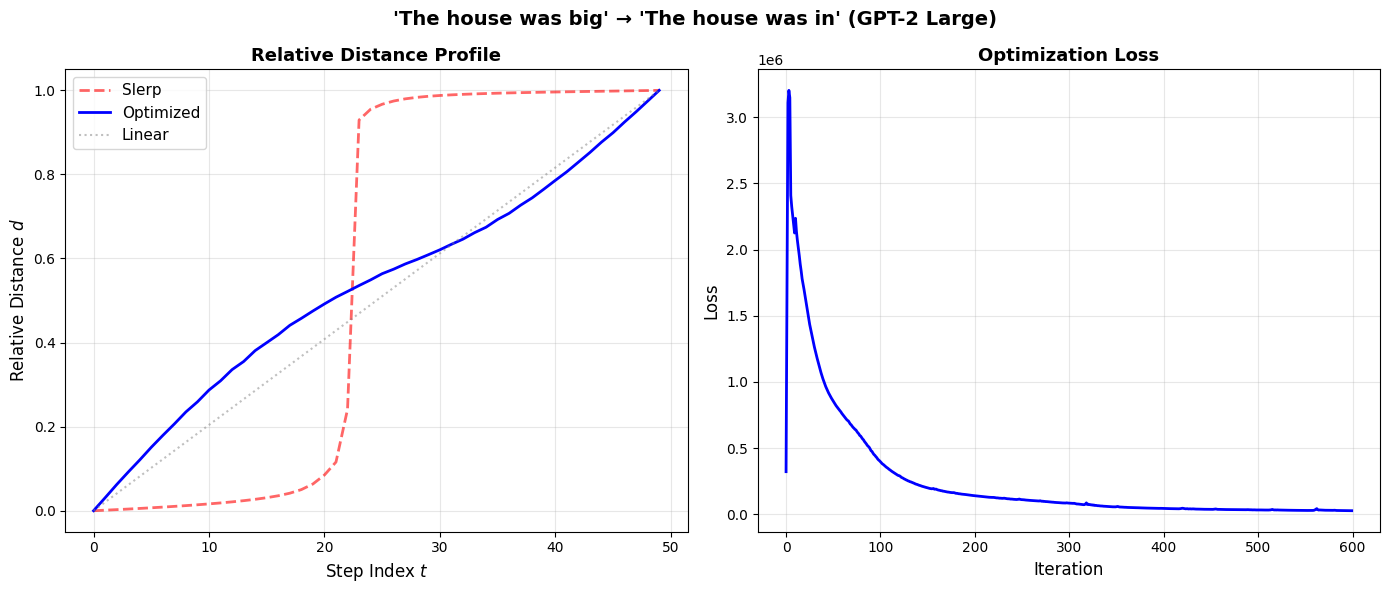


ANALYSIS
Start: d=0.0000 (should be ~0)
End: d=1.0000 (should be ~1)

Deviation from linear:
  Mean: 0.0445
  Max:  0.0952

Derivative statistics:
  Mean: 0.0204
  Std:  0.0061
  Max:  0.0313

Comparison to Stefan's results:
→ SMOOTH transition with GPT-2 Large
   Either: (a) boundaries don't exist, or
           (b) optimization finds smoother paths than slerp


In [ ]:
# --- Test Case: Big vs In (Stefan's Original) ---

prompt_a = "The house was big"
prompt_b = "The house was in"
n_steps = 50
lambda_val = 1.0
lr = 0.05
iterations = 600

print("=" * 60)
print(f"Testing Stefan's original: '{prompt_a}' vs '{prompt_b}'")
print("=" * 60)

# First, check what GPT-2 Large predicts
print("\nTop predictions:")
for prompt in [prompt_a, prompt_b]:
    top_k = get_top_k_tokens(prompt, k=5)
    print(f"\n'{prompt}':")
    for token, prob in top_k:
        print(f"  '{token}': {prob:.4f}")

# Get Layer 0 outputs
resid_a, tokens_a = get_layer0_and_prefix(prompt_a)
resid_b, tokens_b = get_layer0_and_prefix(prompt_b)

print(f"\nSequence length: {resid_a.shape[1]} tokens")
print("\nTokens:")
print(f"A: {tokenizer.convert_ids_to_tokens(tokens_a[0])}")
print(f"B: {tokenizer.convert_ids_to_tokens(tokens_b[0])}")

# These differ on the LAST token
# So we use the last token position
prefix_resid = resid_a[:, :-1, :]  # "The house was"
start_vec = resid_a[:, -1:, :]     # " big"
end_vec = resid_b[:, -1:, :]       # " in"

print(f"\nInterpolating at LAST token position")
print(f"Context (prefix): {prefix_resid.shape[1]} tokens")

# Initialize Path
initial_path = slerp_path(start_vec, end_vec, n_steps)
optimized_path = nn.Parameter(initial_path.clone().detach())
optimizer = optim.Adam([optimized_path], lr=lr)

# --- Optimization Loop ---

print("\nOptimizing path...")
loss_history = []

for i in range(iterations):
    optimizer.zero_grad()

    # For last token case: concatenate prefix then path
    prefix_batch = prefix_resid.expand(optimized_path.shape[0], -1, -1)
    full_sequences = torch.cat([prefix_batch, optimized_path], dim=1)

    hidden = full_sequences
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    current_logits = model.lm_head(hidden[:, -1, :])

    p_flat = optimized_path.squeeze(1)
    diff_input = p_flat[1:] - p_flat[:-1]
    energy_input = torch.sum(diff_input.norm(dim=1)**2)

    diff_output = current_logits[1:] - current_logits[:-1]
    energy_output = torch.sum(diff_output.norm(dim=1)**2)

    loss = energy_input + (lambda_val * energy_output)

    loss.backward()
    optimizer.step()

    with torch.no_grad():
        optimized_path[0].copy_(start_vec.squeeze(0))
        optimized_path[-1].copy_(end_vec.squeeze(0))

    loss_history.append(loss.item())

    if i % 50 == 0:
        print(f"Iter {i:03d}: Loss {loss.item():.2f}")

# --- Get Endpoint Logits ---

with torch.no_grad():
    full_seq_a = torch.cat([prefix_resid, start_vec], dim=1)
    hidden_a = full_seq_a
    for block in model.transformer.h[1:]:
        hidden_a = block(hidden_a)[0]
    hidden_a = model.transformer.ln_f(hidden_a)
    logits_a = model.lm_head(hidden_a[:, -1, :]).squeeze(0)

    full_seq_b = torch.cat([prefix_resid, end_vec], dim=1)
    hidden_b = full_seq_b
    for block in model.transformer.h[1:]:
        hidden_b = block(hidden_b)[0]
    hidden_b = model.transformer.ln_f(hidden_b)
    logits_b = model.lm_head(hidden_b[:, -1, :]).squeeze(0)

# --- Compute Relative Distances ---

def compute_relative_distance_last_token(path_tensor, prefix, logits_a, logits_b):
    """For paths where the last token varies."""
    with torch.no_grad():
        n_steps = path_tensor.shape[0]
        prefix_batch = prefix.expand(n_steps, -1, -1)
        full_sequences = torch.cat([prefix_batch, path_tensor], dim=1)

        hidden = full_sequences
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits_path = model.lm_head(hidden[:, -1, :])

        relative_distances = []
        for logits_x in logits_path:
            dist_to_a = torch.norm(logits_x - logits_a).item()
            dist_to_b = torch.norm(logits_x - logits_b).item()
            rel_dist = dist_to_a / (dist_to_a + dist_to_b)
            relative_distances.append(rel_dist)

        return np.array(relative_distances)

rel_dist_initial = compute_relative_distance_last_token(initial_path, prefix_resid, logits_a, logits_b)
rel_dist_optimized = compute_relative_distance_last_token(optimized_path, prefix_resid, logits_a, logits_b)

# --- Plot ---

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Relative Distance
step_indices = np.arange(n_steps)
ax1.plot(step_indices, rel_dist_initial, label='Slerp',
         color='red', linestyle='--', alpha=0.6, linewidth=2)
ax1.plot(step_indices, rel_dist_optimized, label='Optimized',
         color='blue', linewidth=2)
ax1.plot(step_indices, np.linspace(0, 1, n_steps),
         color='gray', linestyle=':', alpha=0.5, label='Linear')

ax1.set_xlabel("Step Index $t$", fontsize=12)
ax1.set_ylabel("Relative Distance $d$", fontsize=12)
ax1.set_title(f"Relative Distance Profile", fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(-0.05, 1.05)

# Plot 2: Loss History
ax2.plot(loss_history, color='blue', linewidth=2)
ax2.set_xlabel("Iteration", fontsize=12)
ax2.set_ylabel("Loss", fontsize=12)
ax2.set_title("Optimization Loss", fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.suptitle(f"'{prompt_a}' → '{prompt_b}' (GPT-2 Large)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Analysis ---

print("\n" + "=" * 60)
print("ANALYSIS")
print("=" * 60)
print(f"Start: d={rel_dist_optimized[0]:.4f} (should be ~0)")
print(f"End: d={rel_dist_optimized[-1]:.4f} (should be ~1)")

linear_ref = np.linspace(0, 1, n_steps)
deviation = np.mean(np.abs(rel_dist_optimized - linear_ref))
max_deviation = np.max(np.abs(rel_dist_optimized - linear_ref))

print(f"\nDeviation from linear:")
print(f"  Mean: {deviation:.4f}")
print(f"  Max:  {max_deviation:.4f}")

derivatives = np.abs(np.diff(rel_dist_optimized))
print(f"\nDerivative statistics:")
print(f"  Mean: {np.mean(derivatives):.4f}")
print(f"  Std:  {np.std(derivatives):.4f}")
print(f"  Max:  {np.max(derivatives):.4f}")

print("\nComparison to Stefan's results:")
if max_deviation < 0.1:
    print("→ SMOOTH transition with GPT-2 Large")
    print("   Either: (a) boundaries don't exist, or")
    print("           (b) optimization finds smoother paths than slerp")
elif max_deviation < 0.2:
    print("→ WEAK boundary structure")
    print("   Less pronounced than Stefan's GPT-2 results?")
else:
    print("→ STRONG boundary confirmed")
    print("   Consistent with Stefan's original findings")

Let's look at path lengths. Does the optimized path need to deviate a lot in order to achieve its smoothness in comparison with the slerp path?

PATH LENGTH COMPARISON

Distances in activation space:
  Straight line (Euclidean):  19.9547
  Slerp path length:          20.6902
  Optimized path length:      451.9625

Ratios:
  Slerp / Euclidean:          1.0369
  Optimized / Euclidean:      22.6494
  Optimized / Slerp:          21.8443


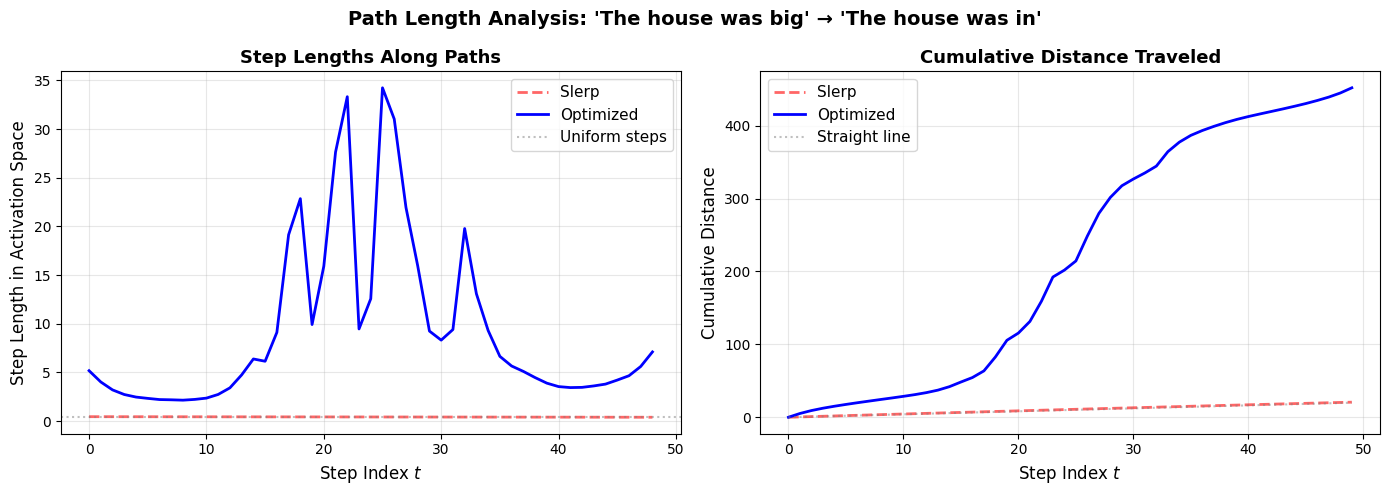

In [ ]:
# --- Test #3: Compare path lengths in activation space ---

print("=" * 60)
print("PATH LENGTH COMPARISON")
print("=" * 60)

# Compute arc length of slerp path
slerp_flat = initial_path.squeeze(1).detach().cpu()
slerp_diffs = slerp_flat[1:] - slerp_flat[:-1]
slerp_lengths = torch.norm(slerp_diffs, dim=1)
slerp_total_length = torch.sum(slerp_lengths).item()

# Compute arc length of optimized path
opt_flat = optimized_path.squeeze(1).detach().cpu()
opt_diffs = opt_flat[1:] - opt_flat[:-1]
opt_lengths = torch.norm(opt_diffs, dim=1)
opt_total_length = torch.sum(opt_lengths).item()

# Straight line distance (Euclidean)
start_flat = start_vec.squeeze().detach().cpu()
end_flat = end_vec.squeeze().detach().cpu()
straight_line_distance = torch.norm(end_flat - start_flat).item()

print(f"\nDistances in activation space:")
print(f"  Straight line (Euclidean):  {straight_line_distance:.4f}")
print(f"  Slerp path length:          {slerp_total_length:.4f}")
print(f"  Optimized path length:      {opt_total_length:.4f}")

print(f"\nRatios:")
print(f"  Slerp / Euclidean:          {slerp_total_length / straight_line_distance:.4f}")
print(f"  Optimized / Euclidean:      {opt_total_length / straight_line_distance:.4f}")
print(f"  Optimized / Slerp:          {opt_total_length / slerp_total_length:.4f}")

# Visualize step lengths along each path
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Step lengths
step_indices = np.arange(len(slerp_lengths))
ax1.plot(step_indices, slerp_lengths.numpy(), label='Slerp',
         color='red', linestyle='--', alpha=0.6, linewidth=2)
ax1.plot(step_indices, opt_lengths.numpy(), label='Optimized',
         color='blue', linewidth=2)
ax1.axhline(y=straight_line_distance/(n_steps-1), color='gray',
           linestyle=':', alpha=0.5, label='Uniform steps')

ax1.set_xlabel("Step Index $t$", fontsize=12)
ax1.set_ylabel("Step Length in Activation Space", fontsize=12)
ax1.set_title("Step Lengths Along Paths", fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Cumulative distance traveled
slerp_cumulative = torch.cumsum(torch.cat([torch.tensor([0.0]), slerp_lengths]), dim=0).numpy()
opt_cumulative = torch.cumsum(torch.cat([torch.tensor([0.0]), opt_lengths]), dim=0).numpy()
linear_cumulative = np.linspace(0, straight_line_distance, n_steps)

step_indices_full = np.arange(n_steps)
ax2.plot(step_indices_full, slerp_cumulative, label='Slerp',
         color='red', linestyle='--', alpha=0.6, linewidth=2)
ax2.plot(step_indices_full, opt_cumulative, label='Optimized',
         color='blue', linewidth=2)
ax2.plot(step_indices_full, linear_cumulative, label='Straight line',
         color='gray', linestyle=':', alpha=0.5)

ax2.set_xlabel("Step Index $t$", fontsize=12)
ax2.set_ylabel("Cumulative Distance", fontsize=12)
ax2.set_title("Cumulative Distance Traveled", fontsize=13, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

plt.suptitle(f"Path Length Analysis: '{prompt_a}' → '{prompt_b}'",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# --- Test #2: Semantic coherence along paths ---

print("=" * 60)
print("INTERMEDIATE OUTPUT ANALYSIS")
print("=" * 60)

# Sample evenly spaced points along each path
sample_indices = [0, 10, 20, 25, 30, 40, 49]  # Include boundary region (20-30)

print(f"\nPrompts: '{prompt_a}' → '{prompt_b}'")
print("=" * 60)

for path_name, path_tensor in [("SLERP", initial_path), ("OPTIMIZED", optimized_path)]:
    print(f"\n{path_name} PATH:")
    print("-" * 60)

    for idx in sample_indices:
        # Get activations at this point
        point = path_tensor[idx:idx+1]

        # Reconstruct full sequence
        with torch.no_grad():
            full_seq = torch.cat([prefix_resid, point], dim=1)

            hidden = full_seq
            for block in model.transformer.h[1:]:
                hidden = block(hidden)[0]
            hidden = model.transformer.ln_f(hidden)
            logits = model.lm_head(hidden[:, -1, :]).squeeze(0)

            # Get top-5 predictions
            probs = torch.softmax(logits, dim=-1)
            top_k_probs, top_k_indices = torch.topk(probs, 5)
            top_k_tokens = [tokenizer.decode([idx.item()]) for idx in top_k_indices]

            # Compute entropy (measure of confidence/coherence)
            entropy = -torch.sum(probs * torch.log(probs + 1e-10)).item()

        print(f"\nStep {idx}/{n_steps-1}:")
        print(f"  Top-5 predictions:")
        for token, prob in zip(top_k_tokens, top_k_probs):
            print(f"    '{token}': {prob.item():.4f}")
        print(f"  Entropy: {entropy:.2f} (lower = more confident)")

print("\n" + "=" * 60)
print("INTERPRETATION")
print("=" * 60)
print("Questions to consider:")
print("1. Do intermediate predictions make semantic sense?")
print("2. Is there higher entropy (less confidence) in middle of optimized path?")
print("3. Do predictions gradually transition, or show discontinuities?")
print("4. Are optimized path predictions less coherent than slerp?")

INTERMEDIATE OUTPUT ANALYSIS

Prompts: 'The house was big' → 'The house was in'

SLERP PATH:
------------------------------------------------------------

Step 0/49:
  Top-5 predictions:
    ' enough': 0.2941
    ',': 0.2395
    ' and': 0.1988
    '.': 0.0834
    ' but': 0.0262
  Entropy: 2.27 (lower = more confident)

Step 10/49:
  Top-5 predictions:
    ' enough': 0.2800
    ',': 0.2424
    ' and': 0.1995
    '.': 0.0869
    ' but': 0.0272
  Entropy: 2.30 (lower = more confident)

Step 20/49:
  Top-5 predictions:
    ',': 0.2887
    ' and': 0.2152
    ' enough': 0.1446
    '.': 0.1202
    ' but': 0.0346
  Entropy: 2.45 (lower = more confident)

Step 25/49:
  Top-5 predictions:
    ' a': 0.2455
    ' the': 0.1508
    ' good': 0.0422
    ' an': 0.0371
    ' dis': 0.0346
  Entropy: 4.50 (lower = more confident)

Step 30/49:
  Top-5 predictions:
    ' a': 0.2458
    ' the': 0.1561
    ' good': 0.0387
    ' an': 0.0383
    ' dis': 0.0323
  Entropy: 4.56 (lower = more confident)

Step 40/4

JACOBIAN ANALYSIS AT PATH START

Analyzing at step 0: 'The house was big'
Activation shape: torch.Size([1, 1, 1280])

Sampling random directions...
  Computed 20/100 random directions
  Computed 40/100 random directions
  Computed 60/100 random directions
  Computed 80/100 random directions
  Computed 100/100 random directions

Computing sensitivity along slerp direction...
Computing sensitivity along optimized path tangent...

RESULTS

Random directions (N=100):
  Mean:   1.27
  Median: 1.20
  Std:    0.29
  Min:    0.84
  Max:    2.50

Known directions:
  Slerp tangent:     1.61
  Optimized tangent: 3.42

Percentile ranking:
  Slerp is higher than 86.0% of random directions
  Optimized is higher than 100.0% of random directions


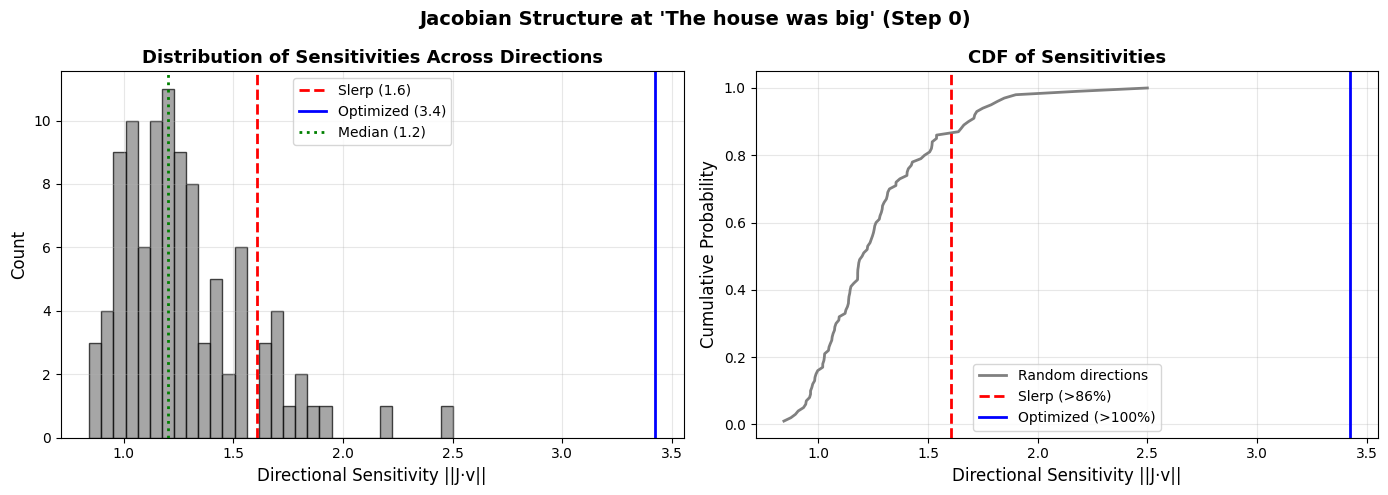

In [ ]:
# --- Characterize Jacobian Structure at Path Start ---

print("=" * 60)
print("JACOBIAN ANALYSIS AT PATH START")
print("=" * 60)

# We'll analyze at step 0 (the "big" endpoint)
analysis_step = 0
point = optimized_path[analysis_step:analysis_step+1].detach()

print(f"\nAnalyzing at step {analysis_step}: '{prompt_a}'")
print(f"Activation shape: {point.shape}")

# Get the logits at this point
with torch.no_grad():
    full_seq = torch.cat([prefix_resid, point], dim=1)
    hidden = full_seq
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    logits_center = model.lm_head(hidden[:, -1, :])

# Function to compute directional derivative
def compute_directional_derivative(point, direction, epsilon=0.01):
    """
    Compute ||∂f/∂x · v|| where v is a unit direction vector.
    Uses finite differences: (f(x + ε·v) - f(x)) / ε
    """
    with torch.no_grad():
        # Perturb in this direction
        perturbed = point + epsilon * direction

        # Get logits at perturbed point
        full_seq = torch.cat([prefix_resid, perturbed], dim=1)
        hidden = full_seq
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits_perturbed = model.lm_head(hidden[:, -1, :])

        # Compute difference and normalize by epsilon
        diff = (logits_perturbed - logits_center) / epsilon
        sensitivity = torch.norm(diff).item()

    return sensitivity

# 1. Sample random directions
print("\nSampling random directions...")
n_random = 100
random_sensitivities = []

activation_dim = point.shape[-1]  # Should be 768 or 1280 for GPT-2 Large

for i in range(n_random):
    # Sample random unit vector
    random_dir = torch.randn(1, 1, activation_dim, device=device)
    random_dir = random_dir / torch.norm(random_dir)

    sensitivity = compute_directional_derivative(point, random_dir)
    random_sensitivities.append(sensitivity)

    if (i + 1) % 20 == 0:
        print(f"  Computed {i+1}/{n_random} random directions")

# 2. Compute sensitivity along slerp direction
print("\nComputing sensitivity along slerp direction...")
slerp_direction = (initial_path[1] - initial_path[0]).unsqueeze(0)
slerp_direction = slerp_direction / torch.norm(slerp_direction)
slerp_sensitivity = compute_directional_derivative(point, slerp_direction)

# 3. Compute sensitivity along optimized path tangent
print("Computing sensitivity along optimized path tangent...")
opt_direction = (optimized_path[1] - optimized_path[0]).unsqueeze(0)
opt_direction = opt_direction / torch.norm(opt_direction)
opt_sensitivity = compute_directional_derivative(point, opt_direction)

# --- Analysis and Visualization ---

print("\n" + "=" * 60)
print("RESULTS")
print("=" * 60)

random_sensitivities = np.array(random_sensitivities)

print(f"\nRandom directions (N={n_random}):")
print(f"  Mean:   {np.mean(random_sensitivities):.2f}")
print(f"  Median: {np.median(random_sensitivities):.2f}")
print(f"  Std:    {np.std(random_sensitivities):.2f}")
print(f"  Min:    {np.min(random_sensitivities):.2f}")
print(f"  Max:    {np.max(random_sensitivities):.2f}")

print(f"\nKnown directions:")
print(f"  Slerp tangent:     {slerp_sensitivity:.2f}")
print(f"  Optimized tangent: {opt_sensitivity:.2f}")

# Percentiles
slerp_percentile = np.mean(random_sensitivities < slerp_sensitivity) * 100
opt_percentile = np.mean(random_sensitivities < opt_sensitivity) * 100

print(f"\nPercentile ranking:")
print(f"  Slerp is higher than {slerp_percentile:.1f}% of random directions")
print(f"  Optimized is higher than {opt_percentile:.1f}% of random directions")

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
ax1.hist(random_sensitivities, bins=30, alpha=0.7, color='gray', edgecolor='black')
ax1.axvline(slerp_sensitivity, color='red', linestyle='--', linewidth=2,
           label=f'Slerp ({slerp_sensitivity:.1f})')
ax1.axvline(opt_sensitivity, color='blue', linestyle='-', linewidth=2,
           label=f'Optimized ({opt_sensitivity:.1f})')
ax1.axvline(np.median(random_sensitivities), color='green', linestyle=':', linewidth=2,
           label=f'Median ({np.median(random_sensitivities):.1f})')

ax1.set_xlabel("Directional Sensitivity ||J·v||", fontsize=12)
ax1.set_ylabel("Count", fontsize=12)
ax1.set_title("Distribution of Sensitivities Across Directions", fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# CDF
sorted_sensitivities = np.sort(random_sensitivities)
cdf = np.arange(1, len(sorted_sensitivities) + 1) / len(sorted_sensitivities)

ax2.plot(sorted_sensitivities, cdf, color='gray', linewidth=2, label='Random directions')
ax2.axvline(slerp_sensitivity, color='red', linestyle='--', linewidth=2,
           label=f'Slerp (>{slerp_percentile:.0f}%)')
ax2.axvline(opt_sensitivity, color='blue', linestyle='-', linewidth=2,
           label=f'Optimized (>{opt_percentile:.0f}%)')

ax2.set_xlabel("Directional Sensitivity ||J·v||", fontsize=12)
ax2.set_ylabel("Cumulative Probability", fontsize=12)
ax2.set_title("CDF of Sensitivities", fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.suptitle(f"Jacobian Structure at '{prompt_a}' (Step 0)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


JACOBIAN ANALYSIS AT PATH START

Analyzing at step 22: 'The house was big'
Activation shape: torch.Size([1, 1, 1280])

Sampling random directions...
  Computed 20/100 random directions
  Computed 40/100 random directions
  Computed 60/100 random directions
  Computed 80/100 random directions
  Computed 100/100 random directions

Computing sensitivity along slerp direction...
Computing sensitivity along optimized path tangent...

RESULTS

Random directions (N=100):
  Mean:   7.64
  Median: 6.75
  Std:    3.05
  Min:    3.74
  Max:    17.41

Known directions:
  Slerp tangent:     65.92
  Optimized tangent: 18.42

Percentile ranking:
  Slerp is higher than 100.0% of random directions
  Optimized is higher than 100.0% of random directions


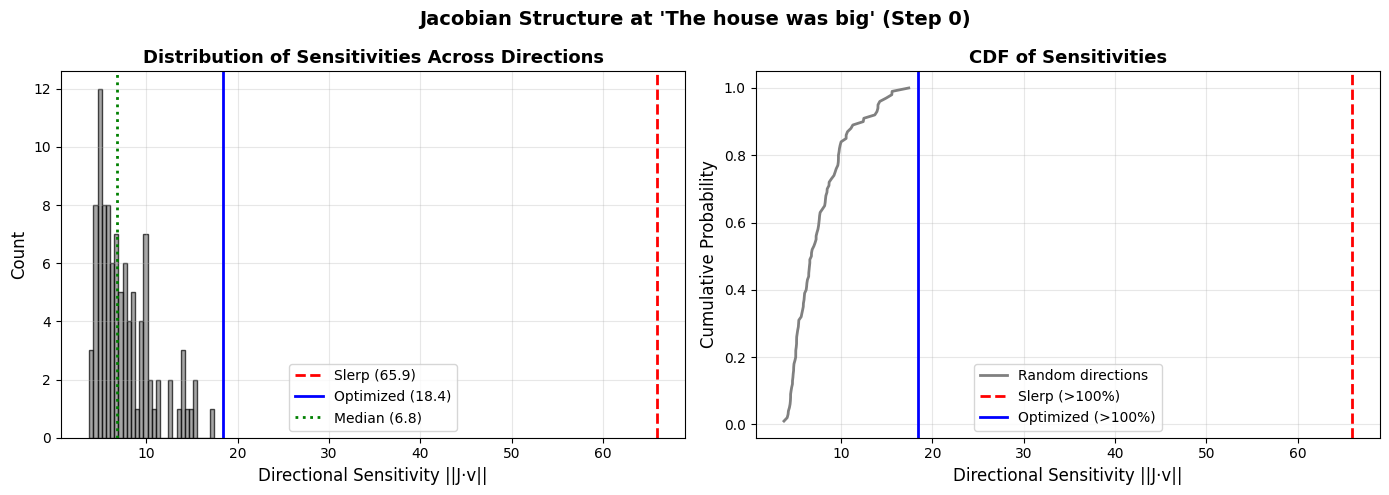

In [ ]:
# --- Characterize Jacobian Structure somewhere around boundary ---

print("=" * 60)
print("JACOBIAN ANALYSIS AT PATH START")
print("=" * 60)

# I estimate by inspection the boundary to be around step 22-23
analysis_step = 22
point = optimized_path[analysis_step:analysis_step+1].detach()

print(f"\nAnalyzing at step {analysis_step}: '{prompt_a}'")
print(f"Activation shape: {point.shape}")

# Get the logits at this point
with torch.no_grad():
    full_seq = torch.cat([prefix_resid, point], dim=1)
    hidden = full_seq
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    logits_center = model.lm_head(hidden[:, -1, :])

# Function to compute directional derivative
def compute_directional_derivative(point, direction, epsilon=0.01):
    """
    Compute ||∂f/∂x · v|| where v is a unit direction vector.
    Uses finite differences: (f(x + ε·v) - f(x)) / ε
    """
    with torch.no_grad():
        # Perturb in this direction
        perturbed = point + epsilon * direction

        # Get logits at perturbed point
        full_seq = torch.cat([prefix_resid, perturbed], dim=1)
        hidden = full_seq
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits_perturbed = model.lm_head(hidden[:, -1, :])

        # Compute difference and normalize by epsilon
        diff = (logits_perturbed - logits_center) / epsilon
        sensitivity = torch.norm(diff).item()

    return sensitivity

# 1. Sample random directions
print("\nSampling random directions...")
n_random = 100
random_sensitivities = []

activation_dim = point.shape[-1]  # Should be 768 or 1280 for GPT-2 Large

for i in range(n_random):
    # Sample random unit vector
    random_dir = torch.randn(1, 1, activation_dim, device=device)
    random_dir = random_dir / torch.norm(random_dir)

    sensitivity = compute_directional_derivative(point, random_dir)
    random_sensitivities.append(sensitivity)

    if (i + 1) % 20 == 0:
        print(f"  Computed {i+1}/{n_random} random directions")

# 2. Compute sensitivity along slerp direction
print("\nComputing sensitivity along slerp direction...")
slerp_direction = (initial_path[1] - initial_path[0]).unsqueeze(0)
slerp_direction = slerp_direction / torch.norm(slerp_direction)
slerp_sensitivity = compute_directional_derivative(point, slerp_direction)

# 3. Compute sensitivity along optimized path tangent
print("Computing sensitivity along optimized path tangent...")
opt_direction = (optimized_path[1] - optimized_path[0]).unsqueeze(0)
opt_direction = opt_direction / torch.norm(opt_direction)
opt_sensitivity = compute_directional_derivative(point, opt_direction)

# --- Analysis and Visualization ---

print("\n" + "=" * 60)
print("RESULTS")
print("=" * 60)

random_sensitivities = np.array(random_sensitivities)

print(f"\nRandom directions (N={n_random}):")
print(f"  Mean:   {np.mean(random_sensitivities):.2f}")
print(f"  Median: {np.median(random_sensitivities):.2f}")
print(f"  Std:    {np.std(random_sensitivities):.2f}")
print(f"  Min:    {np.min(random_sensitivities):.2f}")
print(f"  Max:    {np.max(random_sensitivities):.2f}")

print(f"\nKnown directions:")
print(f"  Slerp tangent:     {slerp_sensitivity:.2f}")
print(f"  Optimized tangent: {opt_sensitivity:.2f}")

# Percentiles
slerp_percentile = np.mean(random_sensitivities < slerp_sensitivity) * 100
opt_percentile = np.mean(random_sensitivities < opt_sensitivity) * 100

print(f"\nPercentile ranking:")
print(f"  Slerp is higher than {slerp_percentile:.1f}% of random directions")
print(f"  Optimized is higher than {opt_percentile:.1f}% of random directions")

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
ax1.hist(random_sensitivities, bins=30, alpha=0.7, color='gray', edgecolor='black')
ax1.axvline(slerp_sensitivity, color='red', linestyle='--', linewidth=2,
           label=f'Slerp ({slerp_sensitivity:.1f})')
ax1.axvline(opt_sensitivity, color='blue', linestyle='-', linewidth=2,
           label=f'Optimized ({opt_sensitivity:.1f})')
ax1.axvline(np.median(random_sensitivities), color='green', linestyle=':', linewidth=2,
           label=f'Median ({np.median(random_sensitivities):.1f})')

ax1.set_xlabel("Directional Sensitivity ||J·v||", fontsize=12)
ax1.set_ylabel("Count", fontsize=12)
ax1.set_title("Distribution of Sensitivities Across Directions", fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# CDF
sorted_sensitivities = np.sort(random_sensitivities)
cdf = np.arange(1, len(sorted_sensitivities) + 1) / len(sorted_sensitivities)

ax2.plot(sorted_sensitivities, cdf, color='gray', linewidth=2, label='Random directions')
ax2.axvline(slerp_sensitivity, color='red', linestyle='--', linewidth=2,
           label=f'Slerp (>{slerp_percentile:.0f}%)')
ax2.axvline(opt_sensitivity, color='blue', linestyle='-', linewidth=2,
           label=f'Optimized (>{opt_percentile:.0f}%)')

ax2.set_xlabel("Directional Sensitivity ||J·v||", fontsize=12)
ax2.set_ylabel("Cumulative Probability", fontsize=12)
ax2.set_title("CDF of Sensitivities", fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.suptitle(f"Jacobian Structure at '{prompt_a}' (Step 0)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


SENSITIVITY ALONG PATHS

Computing sensitivities at each step...
Using 20 random directions per step
  Processing step 0/50...
  Processing step 10/50...
  Processing step 20/50...
  Processing step 30/50...
  Processing step 40/50...


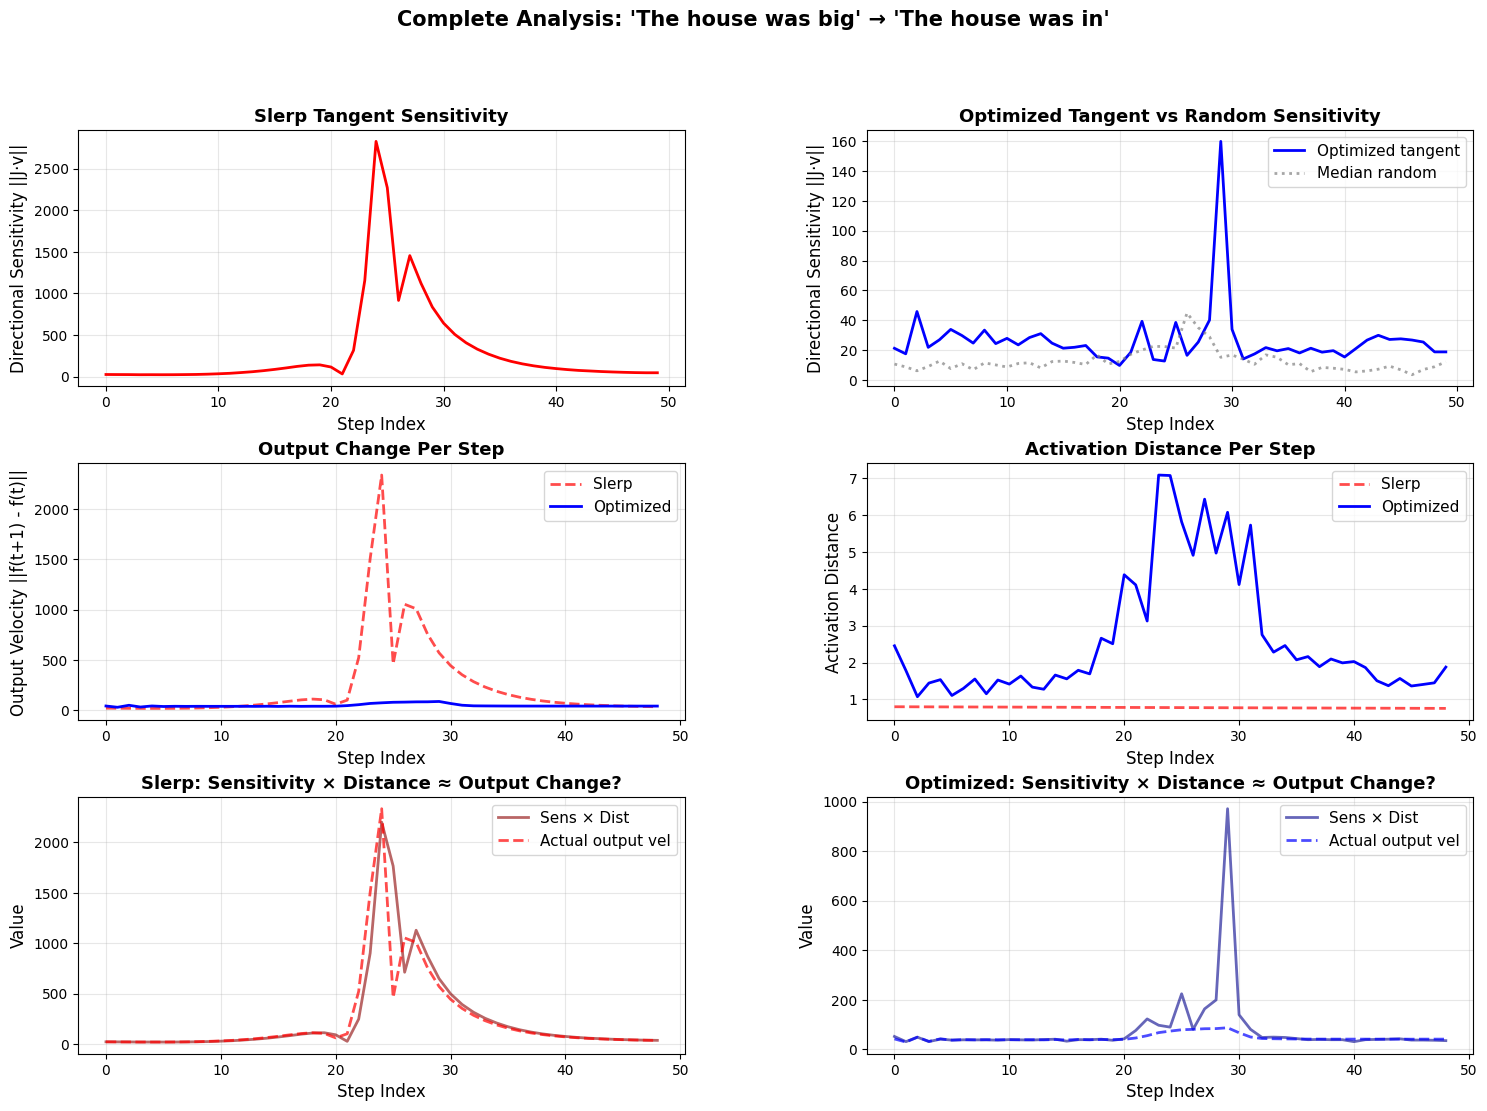


SUMMARY STATISTICS

Slerp tangent sensitivity:
  Mean: 314.72
  Std:  562.83
  Max:  2826.55 (at step 24)
  Min:  23.08 (at step 5)

Optimized tangent sensitivity:
  Mean: 26.59
  Std:  20.46
  Max:  159.83 (at step 29)
  Min:  9.75 (at step 20)

Median random sensitivity:
  Mean: 12.78
  Std:  7.54
  Max:  44.90 (at step 26)
  Min:  3.54 (at step 46)


In [ ]:
# --- Sensitivity vs Step Analysis ---

print("=" * 60)
print("SENSITIVITY ALONG PATHS")
print("=" * 60)

n_random_per_step = 20
epsilon = 0.01

# Storage
slerp_sensitivities = []
opt_sensitivities = []
median_random_sensitivities = []

print(f"\nComputing sensitivities at each step...")
print(f"Using {n_random_per_step} random directions per step")

for step_idx in range(n_steps):
    if step_idx % 10 == 0:
        print(f"  Processing step {step_idx}/{n_steps}...")

    # Get points from each path
    point_slerp = initial_path[step_idx:step_idx+1].detach()
    point_opt = optimized_path[step_idx:step_idx+1].detach()

    # Get logits at these points
    with torch.no_grad():
        # Slerp
        full_seq_slerp = torch.cat([prefix_resid, point_slerp], dim=1)
        hidden = full_seq_slerp
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits_slerp = model.lm_head(hidden[:, -1, :])

        # Optimized
        full_seq_opt = torch.cat([prefix_resid, point_opt], dim=1)
        hidden = full_seq_opt
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits_opt = model.lm_head(hidden[:, -1, :])

    # Compute slerp tangent sensitivity
    if step_idx < n_steps - 1:
        slerp_dir = (initial_path[step_idx+1] - initial_path[step_idx]).unsqueeze(0)
        slerp_dir = slerp_dir / torch.norm(slerp_dir)

        with torch.no_grad():
            perturbed = point_slerp + epsilon * slerp_dir
            full_seq = torch.cat([prefix_resid, perturbed], dim=1)
            hidden = full_seq
            for block in model.transformer.h[1:]:
                hidden = block(hidden)[0]
            hidden = model.transformer.ln_f(hidden)
            logits_perturbed = model.lm_head(hidden[:, -1, :])

            diff = (logits_perturbed - logits_slerp) / epsilon
            slerp_sens = torch.norm(diff).item()
    else:
        slerp_sens = slerp_sensitivities[-1]  # Use previous for last step

    slerp_sensitivities.append(slerp_sens)

    # Compute optimized tangent sensitivity
    if step_idx < n_steps - 1:
        opt_dir = (optimized_path[step_idx+1] - optimized_path[step_idx]).unsqueeze(0)
        opt_dir = opt_dir / torch.norm(opt_dir)

        with torch.no_grad():
            perturbed = point_opt + epsilon * opt_dir
            full_seq = torch.cat([prefix_resid, perturbed], dim=1)
            hidden = full_seq
            for block in model.transformer.h[1:]:
                hidden = block(hidden)[0]
            hidden = model.transformer.ln_f(hidden)
            logits_perturbed = model.lm_head(hidden[:, -1, :])

            diff = (logits_perturbed - logits_opt) / epsilon
            opt_sens = torch.norm(diff).item()
    else:
        opt_sens = opt_sensitivities[-1]

    opt_sensitivities.append(opt_sens)

    # Compute median random sensitivity at optimized path point
    random_sens = []
    activation_dim = point_opt.shape[-1]

    for _ in range(n_random_per_step):
        random_dir = torch.randn(1, 1, activation_dim, device=device)
        random_dir = random_dir / torch.norm(random_dir)

        with torch.no_grad():
            perturbed = point_opt + epsilon * random_dir
            full_seq = torch.cat([prefix_resid, perturbed], dim=1)
            hidden = full_seq
            for block in model.transformer.h[1:]:
                hidden = block(hidden)[0]
            hidden = model.transformer.ln_f(hidden)
            logits_perturbed = model.lm_head(hidden[:, -1, :])

            diff = (logits_perturbed - logits_opt) / epsilon
            random_sens.append(torch.norm(diff).item())

    median_random_sensitivities.append(np.median(random_sens))

# Convert to arrays
slerp_sensitivities = np.array(slerp_sensitivities)
opt_sensitivities = np.array(opt_sensitivities)
median_random_sensitivities = np.array(median_random_sensitivities)

# Compute output velocities
with torch.no_grad():
    # Slerp
    prefix_batch = prefix_resid.expand(initial_path.shape[0], -1, -1)
    full_seq = torch.cat([prefix_batch, initial_path], dim=1)
    hidden = full_seq
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    logits_slerp_all = model.lm_head(hidden[:, -1, :])
    diffs = logits_slerp_all[1:] - logits_slerp_all[:-1]
    vel_slerp = diffs.norm(dim=1).cpu().numpy()

    # Optimized
    prefix_batch = prefix_resid.expand(optimized_path.shape[0], -1, -1)
    full_seq = torch.cat([prefix_batch, optimized_path], dim=1)
    hidden = full_seq
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    logits_opt_all = model.lm_head(hidden[:, -1, :])
    diffs = logits_opt_all[1:] - logits_opt_all[:-1]
    vel_opt = diffs.norm(dim=1).cpu().numpy()

# Compute activation step lengths
slerp_flat = initial_path.squeeze(1).detach().cpu()
slerp_diffs = slerp_flat[1:] - slerp_flat[:-1]
slerp_step_lengths = torch.norm(slerp_diffs, dim=1).numpy()

opt_flat = optimized_path.squeeze(1).detach().cpu()
opt_diffs = opt_flat[1:] - opt_flat[:-1]
opt_step_lengths = torch.norm(opt_diffs, dim=1).numpy()

# --- Plotting ---

fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 2, hspace=0.3, wspace=0.3)

step_indices = np.arange(n_steps)
step_indices_short = np.arange(len(vel_slerp))

# Plot 1: Slerp sensitivity (separate scale)
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(step_indices, slerp_sensitivities,
         color='red', linewidth=2)
ax1.set_xlabel("Step Index", fontsize=12)
ax1.set_ylabel("Directional Sensitivity ||J·v||", fontsize=12)
ax1.set_title("Slerp Tangent Sensitivity", fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Plot 2: Optimized and median random (shared scale)
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(step_indices, opt_sensitivities, label='Optimized tangent',
         color='blue', linewidth=2)
ax2.plot(step_indices, median_random_sensitivities, label='Median random',
         color='gray', linestyle=':', linewidth=2, alpha=0.7)
ax2.set_xlabel("Step Index", fontsize=12)
ax2.set_ylabel("Directional Sensitivity ||J·v||", fontsize=12)
ax2.set_title("Optimized Tangent vs Random Sensitivity", fontsize=13, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)

# Plot 3: Output velocity
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(step_indices_short, vel_slerp, label='Slerp',
         color='red', linestyle='--', linewidth=2, alpha=0.7)
ax3.plot(step_indices_short, vel_opt, label='Optimized',
         color='blue', linewidth=2)
ax3.set_xlabel("Step Index", fontsize=12)
ax3.set_ylabel("Output Velocity ||f(t+1) - f(t)||", fontsize=12)
ax3.set_title("Output Change Per Step", fontsize=13, fontweight='bold')
ax3.legend(fontsize=11)
ax3.grid(True, alpha=0.3)

# Plot 4: Activation step lengths
ax4 = fig.add_subplot(gs[1, 1])
ax4.plot(step_indices_short, slerp_step_lengths, label='Slerp',
         color='red', linestyle='--', linewidth=2, alpha=0.7)
ax4.plot(step_indices_short, opt_step_lengths, label='Optimized',
         color='blue', linewidth=2)
ax4.set_xlabel("Step Index", fontsize=12)
ax4.set_ylabel("Activation Distance", fontsize=12)
ax4.set_title("Activation Distance Per Step", fontsize=13, fontweight='bold')
ax4.legend(fontsize=11)
ax4.grid(True, alpha=0.3)

# Plot 5: Slerp verification (sensitivity × distance vs output velocity)
ax5 = fig.add_subplot(gs[2, 0])
slerp_product = slerp_sensitivities[:-1] * slerp_step_lengths
ax5.plot(step_indices_short, slerp_product, label='Sens × Dist',
         color='darkred', linestyle='-', linewidth=2, alpha=0.6)
ax5.plot(step_indices_short, vel_slerp, label='Actual output vel',
         color='red', linestyle='--', linewidth=2, alpha=0.7)
ax5.set_xlabel("Step Index", fontsize=12)
ax5.set_ylabel("Value", fontsize=12)
ax5.set_title("Slerp: Sensitivity × Distance ≈ Output Change?", fontsize=13, fontweight='bold')
ax5.legend(fontsize=11)
ax5.grid(True, alpha=0.3)

# Plot 6: Optimized verification
ax6 = fig.add_subplot(gs[2, 1])
opt_product = opt_sensitivities[:-1] * opt_step_lengths
ax6.plot(step_indices_short, opt_product, label='Sens × Dist',
         color='darkblue', linestyle='-', linewidth=2, alpha=0.6)
ax6.plot(step_indices_short, vel_opt, label='Actual output vel',
         color='blue', linestyle='--', linewidth=2, alpha=0.7)
ax6.set_xlabel("Step Index", fontsize=12)
ax6.set_ylabel("Value", fontsize=12)
ax6.set_title("Optimized: Sensitivity × Distance ≈ Output Change?", fontsize=13, fontweight='bold')
ax6.legend(fontsize=11)
ax6.grid(True, alpha=0.3)

plt.suptitle(f"Complete Analysis: '{prompt_a}' → '{prompt_b}'",
             fontsize=15, fontweight='bold')
plt.show()

# --- Summary Statistics ---

print("\n" + "=" * 60)
print("SUMMARY STATISTICS")
print("=" * 60)

print(f"\nSlerp tangent sensitivity:")
print(f"  Mean: {np.mean(slerp_sensitivities):.2f}")
print(f"  Std:  {np.std(slerp_sensitivities):.2f}")
print(f"  Max:  {np.max(slerp_sensitivities):.2f} (at step {np.argmax(slerp_sensitivities)})")
print(f"  Min:  {np.min(slerp_sensitivities):.2f} (at step {np.argmin(slerp_sensitivities)})")

print(f"\nOptimized tangent sensitivity:")
print(f"  Mean: {np.mean(opt_sensitivities):.2f}")
print(f"  Std:  {np.std(opt_sensitivities):.2f}")
print(f"  Max:  {np.max(opt_sensitivities):.2f} (at step {np.argmax(opt_sensitivities)})")
print(f"  Min:  {np.min(opt_sensitivities):.2f} (at step {np.argmin(opt_sensitivities)})")

print(f"\nMedian random sensitivity:")
print(f"  Mean: {np.mean(median_random_sensitivities):.2f}")
print(f"  Std:  {np.std(median_random_sensitivities):.2f}")
print(f"  Max:  {np.max(median_random_sensitivities):.2f} (at step {np.argmax(median_random_sensitivities)})")
print(f"  Min:  {np.min(median_random_sensitivities):.2f} (at step {np.argmin(median_random_sensitivities)})")

We want to characterize the sensitivity landscape of GPT-2 Large's output with respect to activations at specific points in activation space. Concretely, we compute the top eigenvalues and eigenvectors of $J^TJ$, where $J$ is the Jacobian of output logits with respect to layer activations. The eigenvalue spectrum tells us how many directions in activation space have high output sensitivity.


In [ ]:
# --- Compute top eigenvalues of J^T J at "The house was big" ---

from scipy.sparse.linalg import eigsh, LinearOperator

print("Computing top eigenvalues of J^T J at starting point...")

# Get starting activation
point = initial_path[0:1].detach().clone()  # Shape: (1, 1, d)
d = point.shape[-1]

# Precompute base logits
with torch.no_grad():
    full_seq = torch.cat([prefix_resid, point], dim=1)
    hidden = full_seq
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    logits_base = model.lm_head(hidden[:, -1, :]).squeeze(0)

def jtj_matvec(v_np):
    """Compute J^T J v where J = d(logits)/d(activation)."""
    v = torch.tensor(v_np, dtype=torch.float32, device=device).reshape(1, 1, d)

    # Jv via finite differences
    eps = 1e-4
    with torch.no_grad():
        full_seq = torch.cat([prefix_resid, point + eps * v], dim=1)
        hidden = full_seq
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits_pert = model.lm_head(hidden[:, -1, :]).squeeze(0)
    Jv = (logits_pert - logits_base) / eps

    # J^T(Jv) via backprop
    act = point.clone().requires_grad_(True)
    full_seq = torch.cat([prefix_resid, act], dim=1)
    hidden = full_seq
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    logits = model.lm_head(hidden[:, -1, :]).squeeze(0)

    (logits * Jv.detach()).sum().backward()
    return act.grad.reshape(-1).cpu().numpy().astype(np.float64)

# Lanczos for top-100
JTJ_op = LinearOperator((d, d), matvec=jtj_matvec, dtype=np.float64)
eigenvalues, eigenvectors = eigsh(JTJ_op, k=100, which='LM')

# Sort descending, convert to singular values
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
singular_values = np.sqrt(np.maximum(eigenvalues, 0))

print(f"Top 10 singular values: {singular_values[:10]}")

Computing top eigenvalues of J^T J at starting point...
Top 10 singular values: [435.24856366  31.7411903   22.32740424  16.0620248   12.24489921
  11.02840507  10.22431636   9.33622683   9.11033771   8.28871939]


In [ ]:
print(f"Top 50 singular values: {singular_values[:50]}")

Top 50 singular values: [435.24856366  31.7411903   22.32740424  16.0620248   12.24489921
  11.02840507  10.22431636   9.33622683   9.11033771   8.28871939
   7.72717924   7.41879917   7.15934063   6.86671737   6.62906066
   6.58371232   6.37687996   6.00591459   5.85914769   5.85654899
   5.66408362   5.62871679   5.51563271   5.38561258   5.23409557
   5.17954578   5.07224202   5.02630326   4.94097924   4.91576881
   4.79602458   4.72714546   4.67633268   4.53204924   4.47178107
   4.42586297   4.38103058   4.25741563   4.24740941   4.1940962
   4.08972821   4.05584606   3.94341489   3.92230282   3.89744764
   3.87154069   3.80042243   3.72932489   3.71585054   3.631675  ]


There's one singular value that's >10x bigger than all others! Seven of them are larger than 10.

How does this compare to the end point of the path? And to the point at the boundary, where the sensitivity is highest? Both in terms of absolute numbers and directions?

Boundary at step 24

Computing at start...
Computing at boundary...
Computing at end...


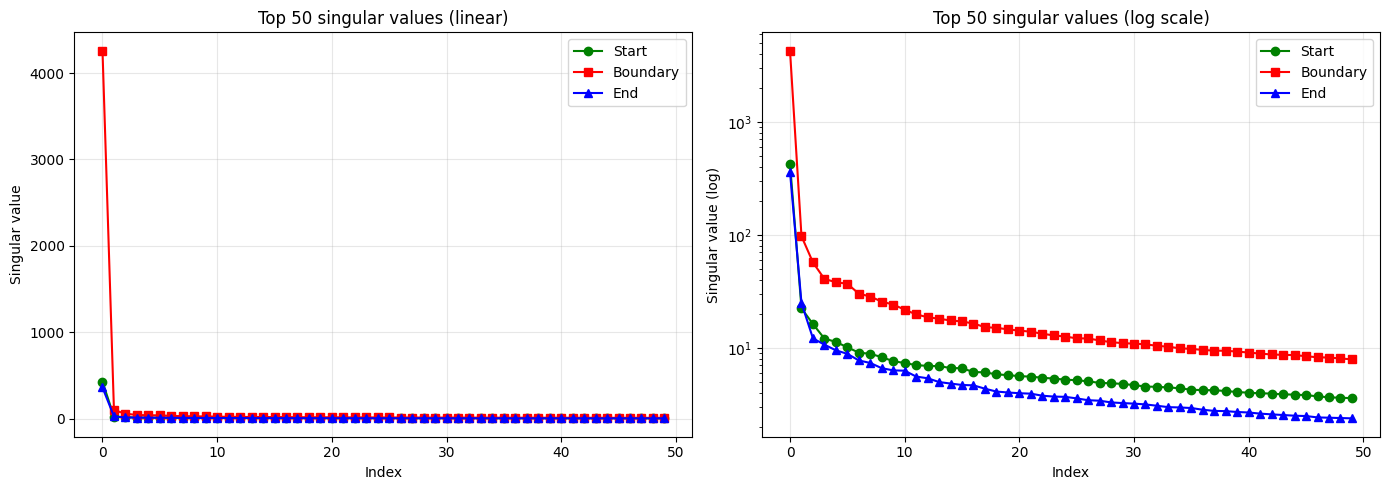


--- Top eigenvector alignment (absolute cosine similarity) ---
Start vs Boundary: 0.1717
Start vs End:      0.2467
Boundary vs End:   0.1135

--- Top-5 subspace alignment ---
Start vs Boundary: 0.2084
Start vs End:      0.0923
Boundary vs End:   0.1399


In [ ]:
# --- Compare eigenspectra at start, boundary, and end ---

def compute_top_eigenvalues(point, k=100):
    """Compute top-k eigenvalues and eigenvectors of J^T J at a point."""
    point = point.detach().clone().reshape(1, 1, d)

    # Precompute base logits
    with torch.no_grad():
        full_seq = torch.cat([prefix_resid, point], dim=1)
        hidden = full_seq
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        base_logits = model.lm_head(hidden[:, -1, :]).squeeze(0)

    def jtj_matvec(v_np):
        v = torch.tensor(v_np, dtype=torch.float32, device=device).reshape(1, 1, d)
        eps = 1e-4
        with torch.no_grad():
            full_seq = torch.cat([prefix_resid, point + eps * v], dim=1)
            hidden = full_seq
            for block in model.transformer.h[1:]:
                hidden = block(hidden)[0]
            hidden = model.transformer.ln_f(hidden)
            logits_pert = model.lm_head(hidden[:, -1, :]).squeeze(0)
        Jv = (logits_pert - base_logits) / eps

        act = point.clone().requires_grad_(True)
        full_seq = torch.cat([prefix_resid, act], dim=1)
        hidden = full_seq
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits = model.lm_head(hidden[:, -1, :]).squeeze(0)
        (logits * Jv.detach()).sum().backward()
        return act.grad.reshape(-1).cpu().numpy().astype(np.float64)

    JTJ_op = LinearOperator((d, d), matvec=jtj_matvec, dtype=np.float64)
    eigenvalues, eigenvectors = eigsh(JTJ_op, k=k, which='LM')

    idx = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[idx]
    eigenvectors = eigenvectors[:, idx]
    singular_values = np.sqrt(np.maximum(eigenvalues, 0))

    return singular_values, eigenvectors

# Find boundary point (max sensitivity along slerp)
boundary_idx = np.argmax(slerp_sensitivities)
print(f"Boundary at step {boundary_idx}")

# Compute at three points
print("\nComputing at start...")
sv_start, ev_start = compute_top_eigenvalues(initial_path[0])

print("Computing at boundary...")
sv_boundary, ev_boundary = compute_top_eigenvalues(initial_path[boundary_idx])

print("Computing at end...")
sv_end, ev_end = compute_top_eigenvalues(initial_path[-1])

# Plot spectra
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear scale
axes[0].plot(sv_start[:50], 'o-', label='Start', color='green')
axes[0].plot(sv_boundary[:50], 's-', label='Boundary', color='red')
axes[0].plot(sv_end[:50], '^-', label='End', color='blue')
axes[0].set_xlabel('Index')
axes[0].set_ylabel('Singular value')
axes[0].set_title('Top 50 singular values (linear)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Log scale
axes[1].semilogy(sv_start[:50], 'o-', label='Start', color='green')
axes[1].semilogy(sv_boundary[:50], 's-', label='Boundary', color='red')
axes[1].semilogy(sv_end[:50], '^-', label='End', color='blue')
axes[1].set_xlabel('Index')
axes[1].set_ylabel('Singular value (log)')
axes[1].set_title('Top 50 singular values (log scale)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Compare top eigenvector alignment
print("\n--- Top eigenvector alignment (absolute cosine similarity) ---")
top1_start = ev_start[:, 0]
top1_boundary = ev_boundary[:, 0]
top1_end = ev_end[:, 0]

print(f"Start vs Boundary: {abs(np.dot(top1_start, top1_boundary)):.4f}")
print(f"Start vs End:      {abs(np.dot(top1_start, top1_end)):.4f}")
print(f"Boundary vs End:   {abs(np.dot(top1_boundary, top1_end)):.4f}")

# Compare top-5 subspace alignment
print("\n--- Top-5 subspace alignment ---")
def subspace_alignment(V1, V2, k=5):
    """Average squared cosine between subspaces."""
    V1 = V1[:, :k]
    V2 = V2[:, :k]
    M = V1.T @ V2
    return np.linalg.norm(M, 'fro')**2 / k

print(f"Start vs Boundary: {subspace_alignment(ev_start, ev_boundary):.4f}")
print(f"Start vs End:      {subspace_alignment(ev_start, ev_end):.4f}")
print(f"Boundary vs End:   {subspace_alignment(ev_boundary, ev_end):.4f}")

Observations:
*   Very sparse at all three points, with the highest eigenvalue being at least one order of magnitude larger than the second
*   As expected, the top singular value at the boundary is much larger than at the plateaus
*   However, the 2nd largest at the boundary is already smaller than the top one at the plateaus! That's how big the largest one is compared to the 2nd largest one across the board
*   Relatively low eigenvector alignment, I think? Start and end have ~0.25 for the top eigenvector. Start and boundary 0.17, boundary and end 0.1135
*   I actually don't have a good reference for how much or little this. Given how high-dimensional the space is, this is much higher than random? Not sure how much to read into it, though
*   Random vectors in 1280 dimensions would have expected absolute cosine similarity around $\sqrt{2/π}/\sqrt{1280}\approx 0.022$


In [ ]:
# Check alignment of slerp direction with top singular vectors

# Slerp direction at boundary
slerp_dir = initial_path[boundary_idx + 1] - initial_path[boundary_idx]
slerp_dir = slerp_dir.reshape(-1).cpu().numpy()
slerp_dir = slerp_dir / np.linalg.norm(slerp_dir)

# Top singular vectors at boundary
top1 = ev_boundary[:, 0]
top5 = ev_boundary[:, :5]

# Alignment with top-1
align_top1 = abs(np.dot(slerp_dir, top1))
print(f"Slerp direction alignment with top-1 singular vector: {align_top1:.4f}")

# Alignment with top-5 subspace
proj = top5 @ (top5.T @ slerp_dir)
align_top5 = np.linalg.norm(proj)
print(f"Slerp direction alignment with top-5 subspace: {align_top5:.4f}")

# For comparison: alignment at start point
slerp_dir_start = initial_path[1] - initial_path[0]
slerp_dir_start = slerp_dir_start.reshape(-1).cpu().numpy()
slerp_dir_start = slerp_dir_start / np.linalg.norm(slerp_dir_start)

align_start_top1 = abs(np.dot(slerp_dir_start, ev_start[:, 0]))
print(f"\nAt start: slerp alignment with top-1: {align_start_top1:.4f}")

Slerp direction alignment with top-1 singular vector: 0.6613
Slerp direction alignment with top-5 subspace: 0.7112

At start: slerp alignment with top-1: 0.0605


Slerp direction alignment with top-1 singular vector: 0.6613
Slerp direction alignment with top-5 subspace: 0.7112

At start: slerp alignment with top-1: 0.0605

The direction of the slerp path is very well aligned with the direction of highest sensitivity at the boundary. It is not at all with the direction of highest sensitivity at the plateau.

Isn't this kind of restating what we already knew? We are aware that as we traverse slerp, there's a plateau followed by a boundary followed by a plateau, where boundary is defined as output changing rapidly...

In [ ]:
# --- What does the top singular vector do to output? ---

# Get top singular vector at start
v1 = torch.tensor(ev_start[:, 0], dtype=torch.float32, device=device).reshape(1, 1, d)

# Base point
point = initial_path[0:1].detach().clone()

# Compute base logits and probabilities
with torch.no_grad():
    full_seq = torch.cat([prefix_resid, point], dim=1)
    hidden = full_seq
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    logits_base = model.lm_head(hidden[:, -1, :]).squeeze(0)
    probs_base = torch.softmax(logits_base, dim=0)

# Perturb in positive and negative direction
epsilon = 50  # Adjust based on activation scale

results = {}
for sign, name in [(1, 'positive'), (-1, 'negative')]:
    with torch.no_grad():
        perturbed = point + sign * epsilon * v1
        full_seq = torch.cat([prefix_resid, perturbed], dim=1)
        hidden = full_seq
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits_pert = model.lm_head(hidden[:, -1, :]).squeeze(0)
        probs_pert = torch.softmax(logits_pert, dim=0)

    prob_diff = probs_pert - probs_base
    results[name] = {
        'probs': probs_pert,
        'diff': prob_diff
    }

# Get tokenizer
tokenizer = model.transformer.wte  # Need actual tokenizer
from transformers import GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

# Show top gainers and losers for positive perturbation
diff = results['positive']['diff'].cpu().numpy()

top_gainers_idx = np.argsort(diff)[-3:][::-1]
top_losers_idx = np.argsort(diff)[:3]

print("=" * 60)
print(f"Perturbation along top singular vector (epsilon={epsilon})")
print("=" * 60)

print("\nBase top-5 predictions:")
top5_base = torch.argsort(probs_base, descending=True)[:5]
for idx in top5_base:
    token = tokenizer.decode([idx])
    print(f"  '{token}': {probs_base[idx].item():.4f}")

print("\n--- POSITIVE direction ---")
print("\nTop probability gainers:")
for idx in top_gainers_idx:
    token = tokenizer.decode([idx])
    print(f"  '{token}': {probs_base[idx].item():.4f} → {results['positive']['probs'][idx].item():.4f} ({diff[idx]:+.4f})")

print("\nTop probability losers:")
for idx in top_losers_idx:
    token = tokenizer.decode([idx])
    print(f"  '{token}': {probs_base[idx].item():.4f} → {results['positive']['probs'][idx].item():.4f} ({diff[idx]:+.4f})")

print("\n--- NEGATIVE direction ---")
diff_neg = results['negative']['diff'].cpu().numpy()
top_gainers_neg = np.argsort(diff_neg)[-3:][::-1]
top_losers_neg = np.argsort(diff_neg)[:3]

print("\nTop probability gainers:")
for idx in top_gainers_neg:
    token = tokenizer.decode([idx])
    print(f"  '{token}': {probs_base[idx].item():.4f} → {results['negative']['probs'][idx].item():.4f} ({diff_neg[idx]:+.4f})")

print("\nTop probability losers:")
for idx in top_losers_neg:
    token = tokenizer.decode([idx])
    print(f"  '{token}': {probs_base[idx].item():.4f} → {results['negative']['probs'][idx].item():.4f} ({diff_neg[idx]:+.4f})")

Perturbation along top singular vector (epsilon=50)

Base top-5 predictions:
  ' enough': 0.4507
  ' and': 0.1839
  ',': 0.1778
  '.': 0.0492
  ' but': 0.0170

--- POSITIVE direction ---

Top probability gainers:
  ' for': 0.0054 → 0.3778 (+0.3723)
  ' on': 0.0035 → 0.1127 (+0.1092)
  ' to': 0.0019 → 0.0366 (+0.0347)

Top probability losers:
  ' enough': 0.4507 → 0.0035 (-0.4472)
  ' and': 0.1839 → 0.0291 (-0.1548)
  ',': 0.1778 → 0.0494 (-0.1284)

--- NEGATIVE direction ---

Top probability gainers:
  ' and': 0.1839 → 0.2453 (+0.0614)
  ' in': 0.0114 → 0.0315 (+0.0201)
  'ly': 0.0003 → 0.0129 (+0.0126)

Top probability losers:
  ' enough': 0.4507 → 0.2449 (-0.2058)
  ' when': 0.0055 → 0.0013 (-0.0042)
  ' so': 0.0051 → 0.0012 (-0.0039)


In [ ]:
def entropy(probs):
    p = probs[probs > 1e-10]
    return -torch.sum(p * torch.log(p)).item()

print(f"Base entropy: {entropy(probs_base):.3f}")
print(f"Positive perturbation: {entropy(results['positive']['probs']):.3f}")
print(f"Negative perturbation: {entropy(results['negative']['probs']):.3f}")

Base entropy: 2.030
Positive perturbation: 2.868
Negative perturbation: 3.339


In [ ]:
# --- Same analysis at boundary point ---

v1_boundary = torch.tensor(ev_boundary[:, 0], dtype=torch.float32, device=device).reshape(1, 1, d)
point_boundary = initial_path[boundary_idx:boundary_idx+1].detach().clone()

# Base logits at boundary
with torch.no_grad():
    full_seq = torch.cat([prefix_resid, point_boundary], dim=1)
    hidden = full_seq
    for block in model.transformer.h[1:]:
        hidden = block(hidden)[0]
    hidden = model.transformer.ln_f(hidden)
    logits_boundary = model.lm_head(hidden[:, -1, :]).squeeze(0)
    probs_boundary = torch.softmax(logits_boundary, dim=0)

# Perturb both directions
epsilon = 50

results_boundary = {}
for sign, name in [(1, 'positive'), (-1, 'negative')]:
    with torch.no_grad():
        perturbed = point_boundary + sign * epsilon * v1_boundary
        full_seq = torch.cat([prefix_resid, perturbed], dim=1)
        hidden = full_seq
        for block in model.transformer.h[1:]:
            hidden = block(hidden)[0]
        hidden = model.transformer.ln_f(hidden)
        logits_pert = model.lm_head(hidden[:, -1, :]).squeeze(0)
        probs_pert = torch.softmax(logits_pert, dim=0)
    results_boundary[name] = {'probs': probs_pert}

print("=" * 60)
print("BOUNDARY POINT ANALYSIS")
print("=" * 60)

print("\nBase top-5 at boundary:")
top5 = torch.argsort(probs_boundary, descending=True)[:5]
for idx in top5:
    token = tokenizer.decode([idx])
    print(f"  '{token}': {probs_boundary[idx].item():.4f}")

print(f"\nEntropy at boundary: {entropy(probs_boundary):.3f}")
print(f"Positive perturbation: {entropy(results_boundary['positive']['probs']):.3f}")
print(f"Negative perturbation: {entropy(results_boundary['negative']['probs']):.3f}")

# Show where each direction takes us
for name in ['positive', 'negative']:
    print(f"\n--- {name.upper()} direction top-5 ---")
    probs = results_boundary[name]['probs']
    top5 = torch.argsort(probs, descending=True)[:5]
    for idx in top5:
        token = tokenizer.decode([idx])
        print(f"  '{token}': {probs[idx].item():.4f}")

BOUNDARY POINT ANALYSIS

Base top-5 at boundary:
  ',': 0.3183
  ' and': 0.2313
  '.': 0.0700
  ' enough': 0.0657
  ' but': 0.0345

Entropy at boundary: 3.033
Positive perturbation: 2.333
Negative perturbation: 5.472

--- POSITIVE direction top-5 ---
  ' enough': 0.3336
  ' and': 0.2391
  ',': 0.1917
  '.': 0.0535
  ' but': 0.0270

--- NEGATIVE direction top-5 ---
  ' the': 0.2624
  ' a': 0.1114
  ' need': 0.0149
  ' an': 0.0147
  ' its': 0.0114
